# WERM-CV: empirical performance and a state-evolution prediction

Only **unpenalized WERM with exhaustive interlaced 10-fold CV** is studied.
There is no adjusted estimator and no search penalty. Training, segment refits,
and final partition searches use squared loss; **only the held-out score uses
absolute error**. This reproduces the loss convention of the canonical M2 and
E_L experiments.

The user-approved theory-focused designs retain the original data-generating
mechanisms and locations, use $p=200$ and $n<3000$, and impose a minimum fitted
segment size so that every segment-refit sampling ratio is greater than one:

| Experiment | Dimension | Sample sizes | True locations | Candidate segments |
|---|---:|---|---|---|
| M2 | $p=200$ | $n\in\{1800,2200,2600\}$, $n/p\in\{9,11,13\}$ | $(0.20,0.50)n$ | $k=1,\ldots,4$ |
| E_L upper bound | $p=200$ | $n=2400$, $n/p=12$ | $(0.20,0.50,0.80)n$ | $k=1,\ldots,L$, $L=1,\ldots,6$ |

Each setting uses **100 datasets** and **20 independent SE realizations** of the
final full-data partition per dataset. The empirical and theoretical predictions
share the true signal matrix and frozen sample weights; the theory never receives
empirical fitted coefficients, estimated partitions, validation scores, or selected
counts. The oracle signal-strength matrix is used only for assessing the theory.

**Interpretation.** This is a first-order SE *extension to the CV pipeline*.
It composes the paper's weighted-fit characterization with a population partition
search, a uniform-weight segment-refit risk, and a CV argmin. It is not presented
as an already-proved finite-sample theorem for CV count-selection frequencies.
Data-selected segment refits require stability, and selection requires separated
limiting risk minimizers. All empirical outcomes and numerical discrepancies are
retained; no parameters are tuned to improve agreement.

## What the empirical CV procedure does

For each candidate segment count $k$ and held-out interlaced fold $v$:

1. Fit the $k$ weighted regressions on the ordered training observations, using
   weights conditional on exactly $k$ segments, and search for $k-1$ boundaries.
2. Map the training boundaries to the original observation indices.
3. Refit an ordinary squared-loss regression in each estimated segment using
   training observations only, with uniform within-segment sample weights.
4. Sum absolute prediction errors on the held-out observations. After all ten
   folds, divide by $n$ to report the normalized CV score.
5. Choose the candidate with the smallest score (smaller $k$ breaks exact ties),
   then rerun fixed-count WERM on all observations at that selected $k$.

Candidate scores are computed once per dataset. E_L selection at upper bound
$L$ uses the prefix $1,\ldots,L$ of that same score vector. The sampling scheme,
index mapping, and refit/scoring losses match `weighted_erm_joint_cv`. The new
minimum-size constraint is applied consistently in the empirical and theoretical
training searches and in both full-data searches. The optimized additive-loss
dynamic program is independently checked against exhaustive constrained search.

M2 retains `SparseDiffSignal(8, sqrt(400*delta), 0.3, 4)` and Gaussian noise with
variance $0.1$; the prior rescales changed coefficient entries as in the original
notebook. E_L retains its four-state Gaussian coefficient random walk and noise
standard deviation $0.5$. Both use $X_{ij}\sim N(0,1/n)$.
For a dataset with $n$ observations, set the minimum segment fraction to
$240/(0.9n)$. Every fitted segment, **including the first and last**, must contain
at least the ceiling of this fraction times the fitting sample size. Thus a
training segment has at least 240 observations ($m_s/p\ge1.2$), and a full-data
segment has at least 267 (integer ceilings are applied directly). The marginal weights are exact uniform-prior
probabilities over integer compositions satisfying these same minimum sizes.
They are frozen and shared by empirical and theoretical fits.

These constraints and weights deliberately differ from the canonical notebooks'
internal-boundary-only spacing and interpolated marginals. This is a documented
companion design for the CV theory experiment, not a rerun of the original curves.

## SE construction and paper cross-reference

The source is `../WERM-paper/JRSSB-revision-rebuttal/JRSSB_v2.tex`: the
squared-loss equations `eq:ls-b-linear-model`–`eq:ls-kappa-linear-model`, the
fit representation `eq:ls-Theta-tilde`, the expected residual profile `eq:ls-v`,
and the population partition objective `eq:ls-F`. The CV convention is described
at `par:CV` and in `sec:sensitivity-number-of-change-points`.

Let $m$ be the training-fold size and $\rho=m/n$. To use the paper's design
normalization, set $\widetilde X=X_{\rm train}/\sqrt\rho$ and
$\widetilde B=\sqrt\rho B$. Then the predictors are unchanged,
$\delta_{\rm train}=m/p$, and
$$\Gamma_{\rm train}=\widetilde B^\top\widetilde B/m=B^\top B/n=\Gamma.$$
There is no spurious factor $n/m$ in the signal-strength matrix.

For each candidate $k$, solve the squared-loss SE using its exact training-fold
weights and the true regime labels in training order. With half-squared loss,
$$\frac1m\sum_i\frac1{1+b_\ell\pi_{i\ell}}=1-\delta_{\rm train}^{-1},
\qquad \omega_{i\ell}=\frac{b_\ell\pi_{i\ell}}{1+b_\ell\pi_{i\ell}}.$$
The paper's unhalved squared loss merely rescales $b$; it leaves the fits,
$\omega$, $\Lambda$, $K$, and all predictions below unchanged.
The true dimension is kept separate from the fitted dimension: $\Gamma$ is
$R\times R$, $\Lambda$ is $R\times k$, and $K$ is $k\times k$, with $R=3$ in M2
and $R=4$ in E_L.

The theoretical training partition minimizes the sum of expected residual profiles
over the same admissible fixed-count partitions:
$$v_{i\ell}=(1-\omega_{i\ell})^2\left[
(\lambda_\ell-e_{r_i})^\top\Gamma(\lambda_\ell-e_{r_i})
+K_{\ell\ell}+\sigma^2\right].$$
This uses the SE mean objective, rather than independently sampling noisy CV
scores and taking their argmin. The latter would silently invent a dependence
structure between candidate scores.

### Uniform-weight segment refits and absolute held-out risk

For each theoretically predicted segment $s$, let $m_s$ be its training size,
$\delta_s=m_s/p$, and $q_s$ its vector of true-regime proportions among training
rows. Uniform-weight squared-loss SE has the closed form
$$\lambda_s=q_s,\qquad
\kappa_s=\frac{\sigma^2+\sum_r q_{sr}\Gamma_{rr}-q_s^\top\Gamma q_s}
{\delta_s-1},\qquad \delta_s>1.$$
The numerator includes the effect of mixing true regimes inside a fitted segment.
For a held-out observation from true regime $r$ assigned to segment $s$,
$$R_{sr}^{\rm abs}=\sqrt{\frac2\pi}\,
\sqrt{\sigma^2+(q_s-e_r)^\top\Gamma(q_s-e_r)+\kappa_s}.$$
Average these risks over the actual held-out regime/segment overlaps and then
over folds. The resulting theoretical score vector selects its own count.
The absolute loss is evaluated as an observable of the squared-loss refit;
there is no absolute-loss regression or absolute-loss fixed-point solve.

At the theory-selected count, recompute SE at the **full-data** sampling ratio
and weights. Draw independent $Z_i\sim N(0,\Gamma)$, $G_i\sim N(0,K)$ and noise,
construct the proximal fitted values from `eq:ls-Theta-tilde`, and apply the same
fixed-count partition search. These 20 draws describe the final localization
prediction conditional on the first-order theory-selected count.

For fixed candidate and fold counts, a finite union bound combines concentration
of the fold scores without requiring fold independence. A separated limiting
minimum then transfers it to count selection. This construction still assumes
stability of the training partition and its data-selected segment refits; those
steps are not supplied automatically by a theorem for fixed weights. The
minimum-size prior also creates zero-weight regions, whereas the paper's stated
regularity assumption requires weights positive almost everywhere. A rigorous
extension must relax that condition using sufficient positive support and
curvature; numerical root/support diagnostics do not replace this justification.
Near-tied
risks and unsupported $\delta_s\le1$ must be reported, not hidden by dropping a
candidate or substituting a different refit model.

In [1]:
# Run from WeightedERM-reference. Missing checkpoints are computed; completed ones are reused.
import os
for key in ('OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS'):
    os.environ[key]='1'
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from tools import werm_cv_theory_experiment as experiment
ROOT, SPEC, WEIGHTS = experiment.prepare(trials=100,theory_draws=20)
JOBS=int(os.environ.get('WERM_CV_THEORY_JOBS','12'))
RESULTS=experiment.run(ROOT,SPEC,WEIGHTS,jobs=JOBS)
print('Results:',ROOT)
print('Trials per setting:',SPEC.get('trials',100))
print('Theory draws per final fit:',SPEC.get('theory_draws',20))
display(pd.DataFrame(SPEC['settings'])[['experiment','n','p','delta','max_segments','minimum_segment_fraction']])

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.


[Parallel(n_jobs=12)]: Done   1 tasks      | elapsed:    2.0s
[Parallel(n_jobs=12)]: Done   8 tasks      | elapsed:    2.2s


[Parallel(n_jobs=12)]: Done  17 tasks      | elapsed:    2.3s
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    2.3s
[Parallel(n_jobs=12)]: Done  37 tasks      | elapsed:    2.3s
[Parallel(n_jobs=12)]: Batch computation too fast (0.18207690620529252s.) Setting batch_size=2.
[Parallel(n_jobs=12)]: Done  48 tasks      | elapsed:    2.4s
[Parallel(n_jobs=12)]: Done  61 tasks      | elapsed:    2.4s


[Parallel(n_jobs=12)]: Done  76 tasks      | elapsed:    2.6s
[Parallel(n_jobs=12)]: Done 106 tasks      | elapsed:    2.7s
[Parallel(n_jobs=12)]: Batch computation too fast (0.19830101710923417s.) Setting batch_size=4.
[Parallel(n_jobs=12)]: Done 136 tasks      | elapsed:    2.8s


[Parallel(n_jobs=12)]: Done 172 tasks      | elapsed:    3.1s
[Parallel(n_jobs=12)]: Done 240 tasks      | elapsed:    3.2s


[Parallel(n_jobs=12)]: Done 316 tasks      | elapsed:    3.7s


[Parallel(n_jobs=12)]: Done 368 tasks      | elapsed:    4.2s
[Parallel(n_jobs=12)]: Done 400 out of 400 | elapsed:    4.3s finished


Results: results/E-WERM-CV-theory/ed5fc8b279bb
Trials per setting: 100
Theory draws per final fit: 20


,experiment,n,p,delta,max_segments,minimum_segment_fraction
0,M2,1800,200,9.0,4,0.148148
1,M2,2200,200,11.0,4,0.121212
2,M2,2600,200,13.0,4,0.102564
3,EL,2400,200,12.0,6,0.111111


## Tables and plotting conventions

WERM-CV is black. SE predictions are blue diamond scatter markers (`d`) with
white edges, without connecting lines or error bars, following the SE estimation
plotting notebook. Empirical bars show absolute distances from the mean to the
first and third quartiles; they are not confidence intervals. The canvas, fonts,
axis labels, and marker sizes follow the canonical M1/M2/M3 style.

Hausdorff distance is divided by $n$ and is reported conditional on a nonempty
estimate. Count summaries retain empty estimates. Theory count predictions have
one selected count per signal matrix, not 20 independent CV selections. The 20
final SE draws contribute to localization only.

,experiment,x,source,trials,mean_count,correct_count,empty,mean_haus,localization_draws,finite_localization_draws
0,M2,9.0,empirical,100,1.95,0.27,0,0.20793,100,100
1,M2,9.0,theory,100,2.04,0.26,0,0.21063,2000,2000
2,M2,11.0,empirical,100,2.29,0.25,0,0.19930,100,100
3,M2,11.0,theory,100,2.48,0.30,0,0.18177,2000,2000
4,M2,13.0,empirical,100,2.49,0.33,0,0.16000,100,100
5,M2,13.0,theory,100,2.55,0.33,0,0.15969,2000,2000
6,EL,1.0,empirical,100,0.00,0.00,100,NaN,100,0
7,EL,1.0,theory,100,0.00,0.00,100,NaN,2000,0
8,EL,2.0,empirical,100,1.00,0.00,0,0.30104,100,100
9,EL,2.0,theory,100,1.00,0.00,0,0.30119,2000,2000


M2_count_match


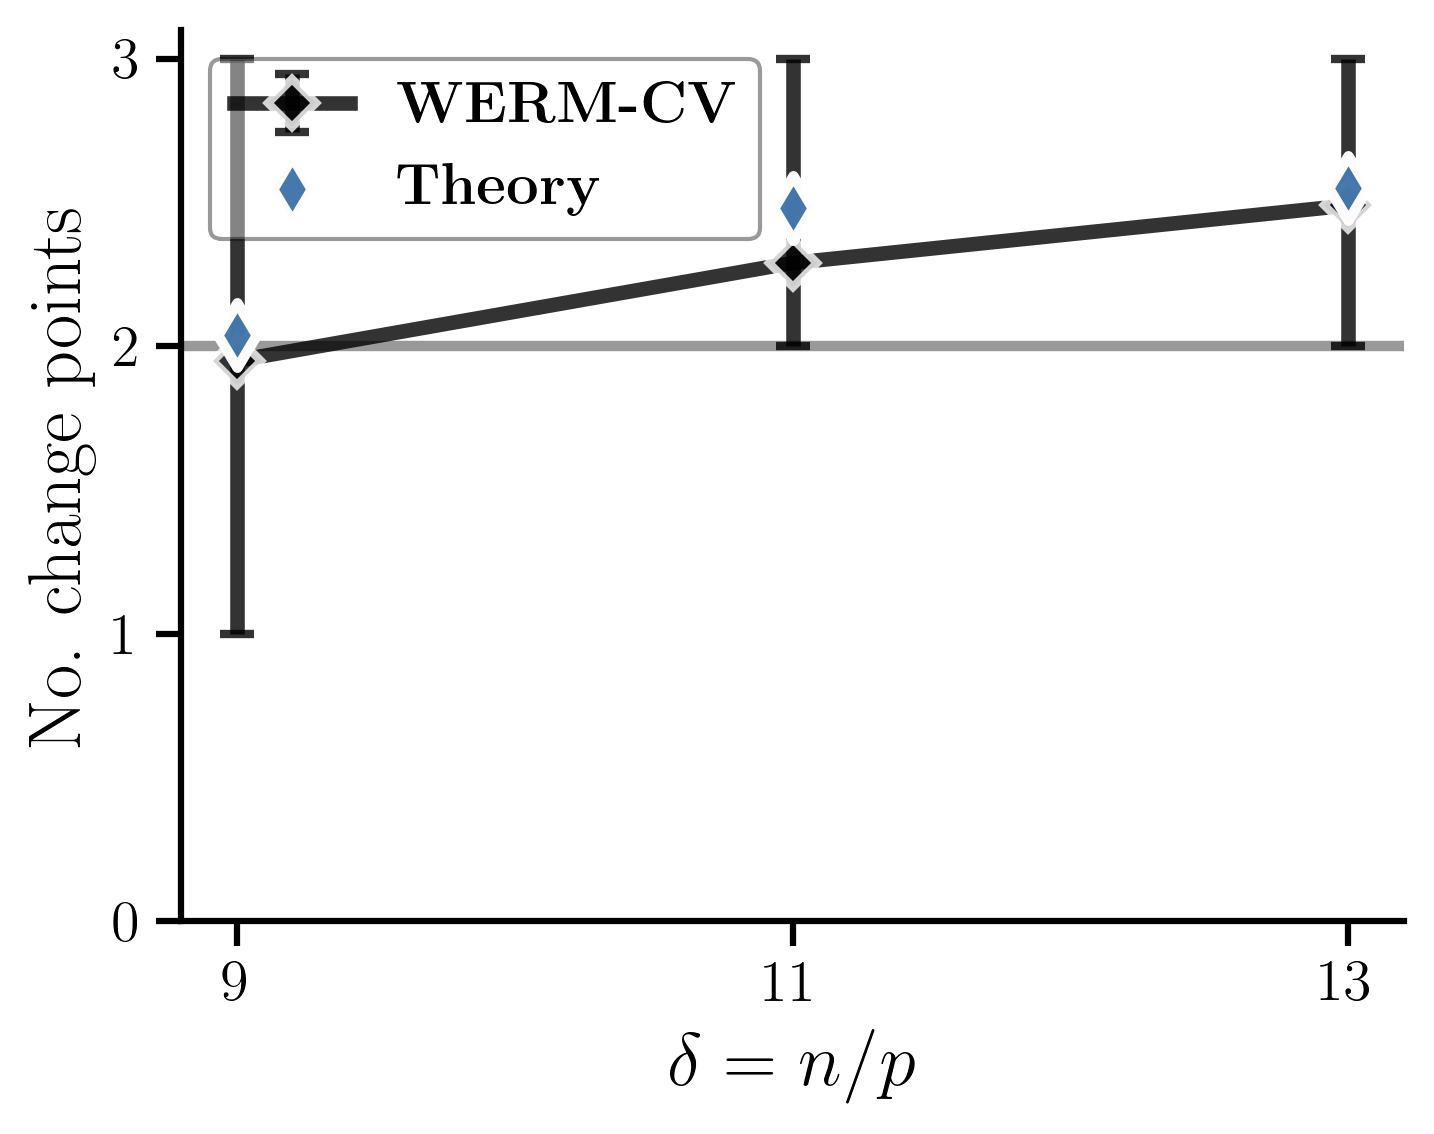

M2_haus_match


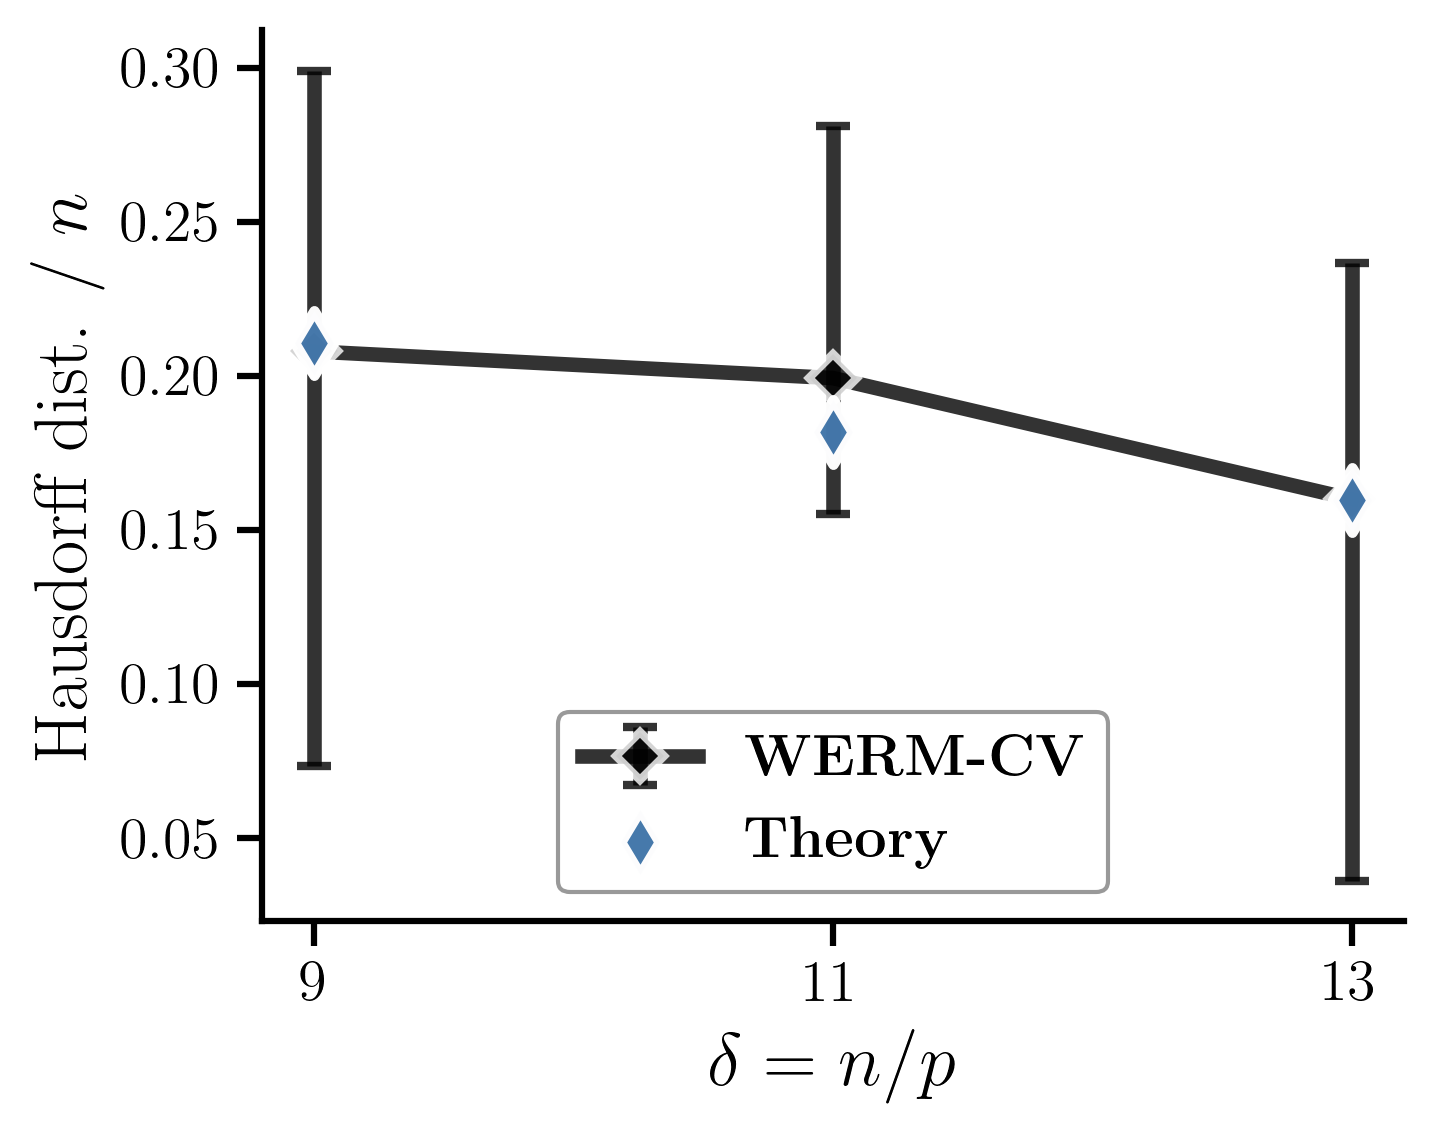

EL_count_match


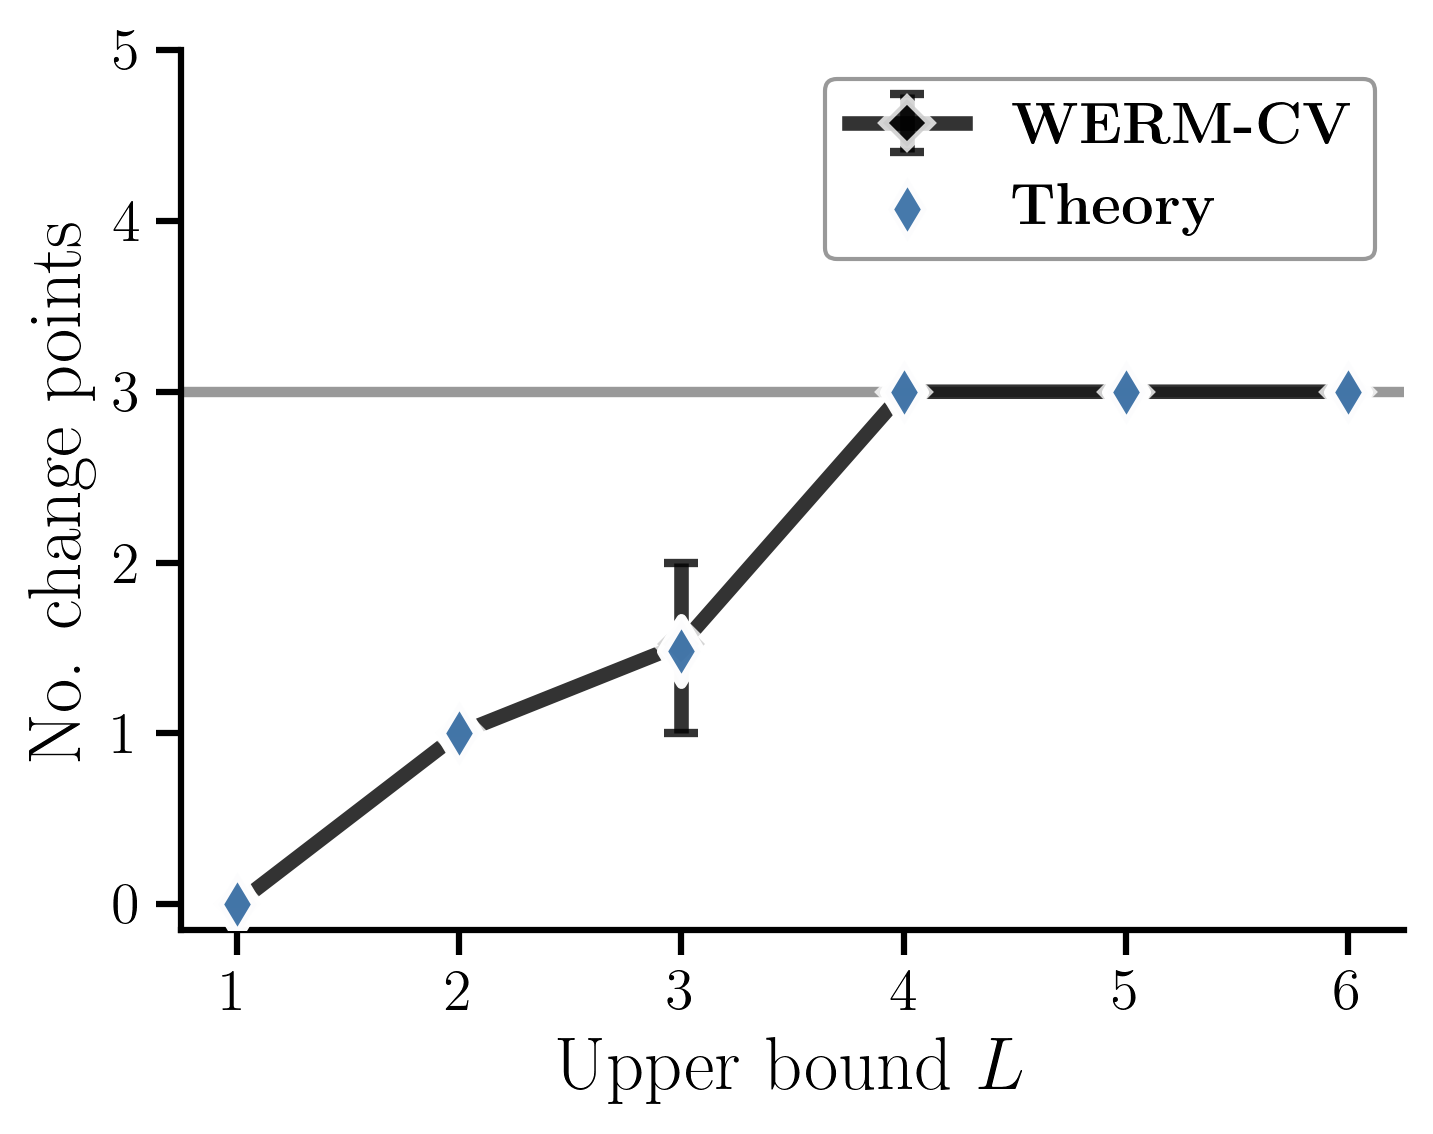

EL_haus_match


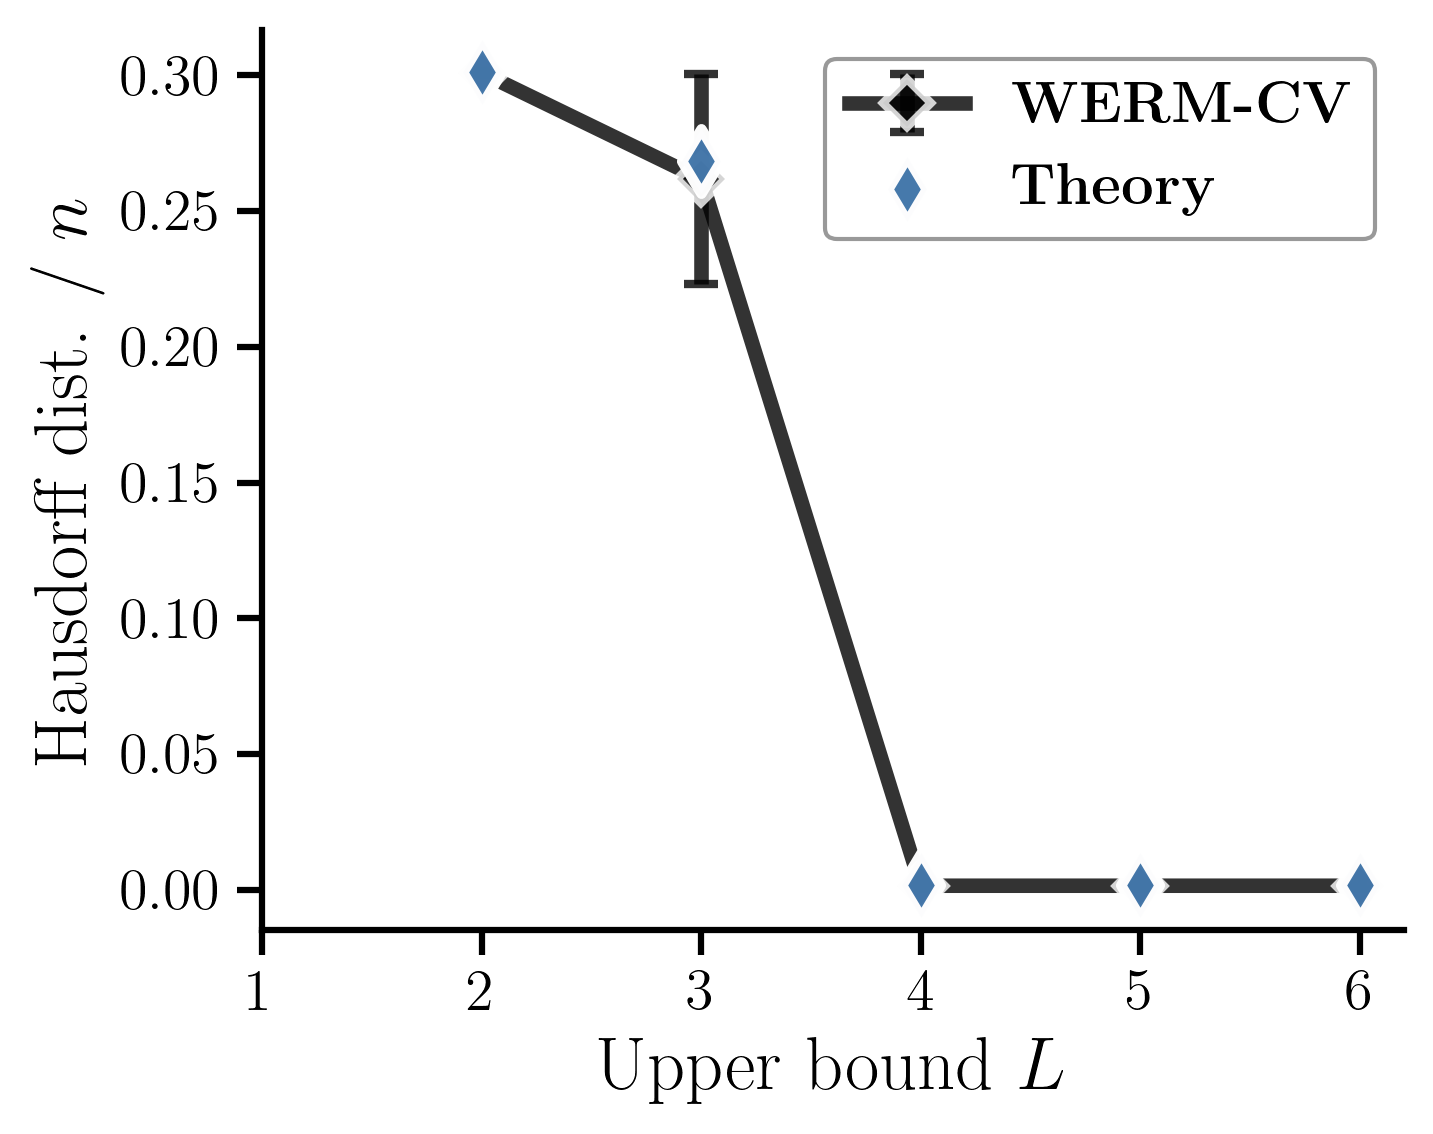

In [2]:
import tools.consistent_plotting as style
import matplotlib.pyplot as plt
style.OUTPUT_DIR=ROOT/'figures'
style.SOURCE_HASHES.clear();style.FIGURE_AUDIT.clear()
SAVED=style.load_saved(ROOT/'results.pkl')
RECORDS=SAVED['records']
LABELS=(r'\textbf{WERM-CV}',r'\textbf{Theory}')
COLORS=('black','#4477AA')

def selection(record,source,bound):
    return record[source]['selected_by_bound'][bound]

def outcomes(record,source,bound):
    selected=selection(record,source,bound)
    if source=='empirical':
        return [selected]
    return selected.get('final_fits',[])

def groups(records,source,bound,metric):
    if metric=='count':
        return np.array([selection(r,source,bound)['selected_segments']-1 for r in records],float)
    return np.array([f[metric] for r in records for f in outcomes(r,source,bound)],float)

def settings(name):
    subset=[r for r in RECORDS if r['experiment']==name]
    if name=='M2':
        return [(float(d),[r for r in subset if r['delta']==d],4)
                for d in sorted(set(r['delta'] for r in subset))]
    return [(L,subset,L) for L in range(1,7)]

summary_rows=[]
for name in ('M2','EL'):
    for x,records,bound in settings(name):
        true_count=len(records[0]['truth'])
        for source in ('empirical','theory'):
            counts=groups(records,source,bound,'count')
            haus=groups(records,source,bound,'haus');finite=haus[np.isfinite(haus)]
            summary_rows.append(dict(experiment=name,x=x,source=source,trials=len(records),
                mean_count=counts.mean(),correct_count=np.mean(counts==true_count),
                empty=int(np.sum(counts==0)),mean_haus=finite.mean() if len(finite) else np.nan,
                localization_draws=len(haus),finite_localization_draws=len(finite)))
SUMMARY=pd.DataFrame(summary_rows)
SUMMARY.to_csv(ROOT/'notebook_summary.csv',index=False)
display(SUMMARY.round(5))

def show_match(name):
    panels=settings(name);x=[s[0] for s in panels]
    for metric,ylabel in [('count','No. change points'),('haus',r'Hausdorff dist. / $n$')]:
        with plt.rc_context(style.CANONICAL_STYLE):
            fig,ax=plt.subplots(figsize=(5,4));fig._canonical_m1=True
            empirical=[groups(records,'empirical',bound,metric) for _,records,bound in panels]
            theory=[groups(records,'theory',bound,metric) for _,records,bound in panels]
            style.error_series(ax,x,empirical,LABELS[0],COLORS[0],'D','-',scale=1)
            means=[np.mean(v[np.isfinite(v)]) if np.isfinite(v).any() else np.nan for v in theory]
            ax.scatter(x,means,label=LABELS[1],marker='d',color=COLORS[1],s=120,
                       edgecolor='white',linewidth=2.5,alpha=.99,zorder=5)
            ax.set(xlabel=r'$\delta=n/p$' if name=='M2' else r'Upper bound $L$',
                   ylabel=ylabel,xticks=x)
            if metric=='count':
                ax.axhline(len(panels[0][1][0]['truth']),color='gray',alpha=.8,lw=2.5,zorder=0)
                ax.set_yticks(range(4 if name=='M2' else 6))
            handles,labels=ax.get_legend_handles_labels()
            ax.legend([handles[labels.index(l)] for l in LABELS],LABELS,
                      loc='best',prop={'size':14},framealpha=.4)
            fig.tight_layout();style.export_plot(fig,name+'_'+metric+'_match')

show_match('M2')
show_match('EL')

## Candidate-score agreement and count-selection stability

Agreement of selected counts can hide differences in validation risks. These
panels compare the normalized absolute-error CV score for every candidate count.
The theory constructs each score independently of the observed CV scores.
For E_L the same six scores determine all six upper-bound selections.

The diagnostic table reports agreement of the empirical and theory-selected
counts, the mean absolute candidate-score discrepancy, and the gaps between
the smallest and second-smallest scores. Small gaps indicate sensitivity to
finite-sample fluctuations; matching first-order risk curves does not by itself
prove a match of finite-sample selection probabilities.

M2_scores_9


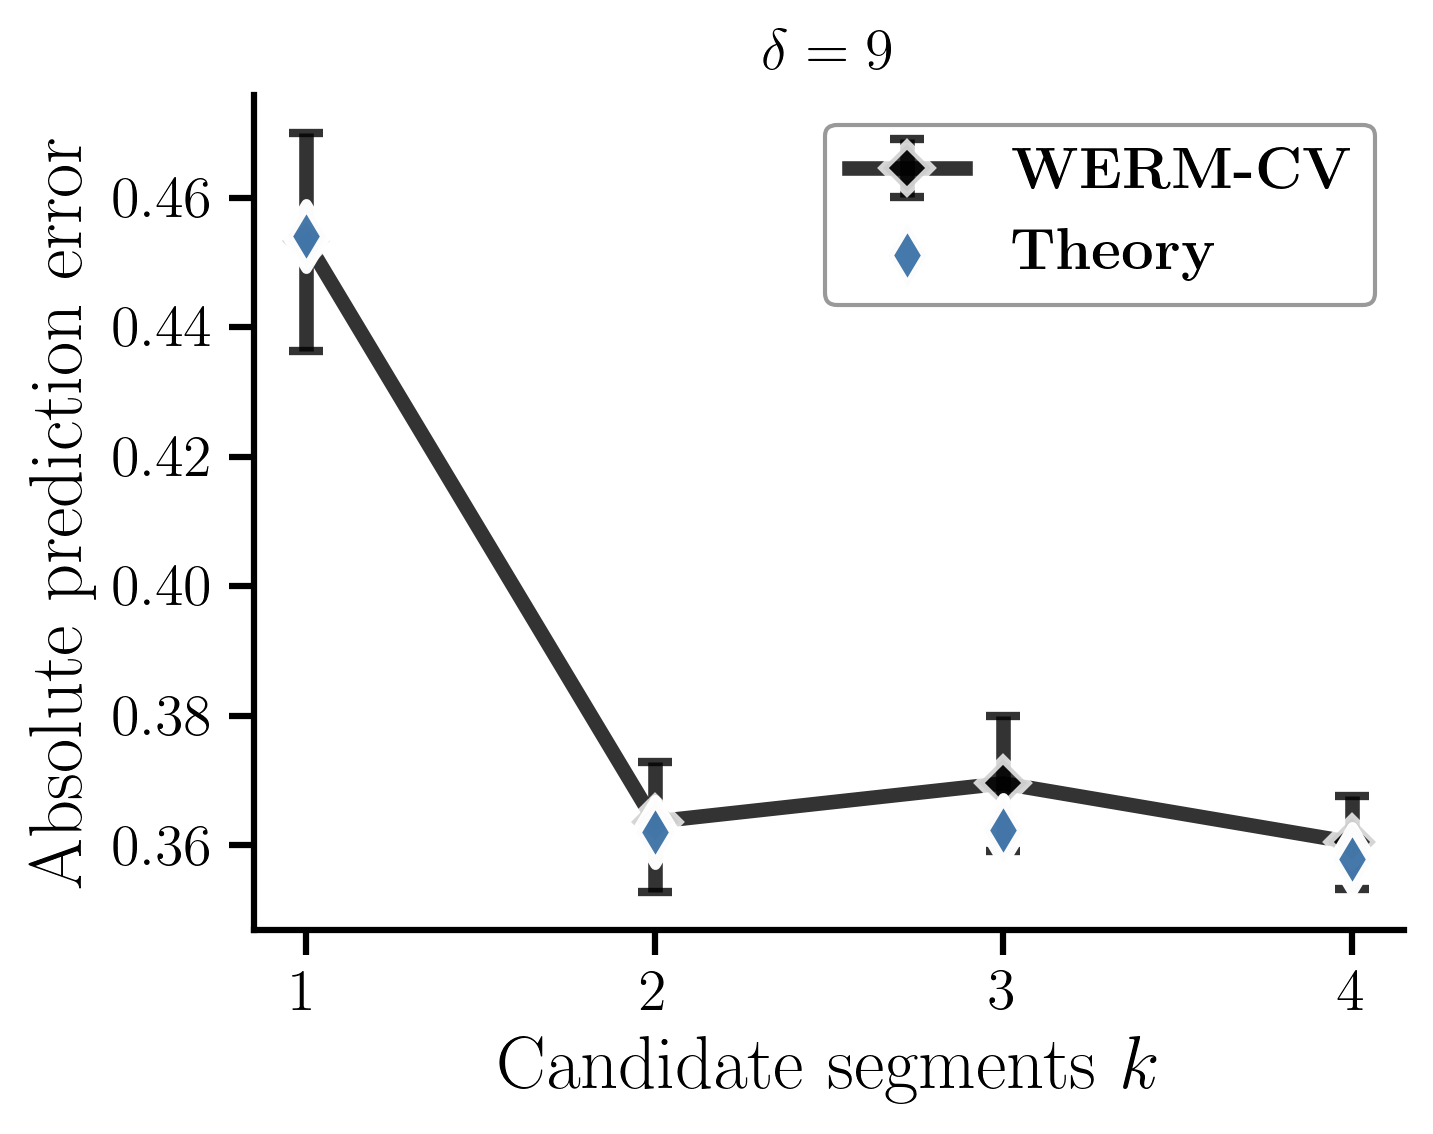

M2_scores_11


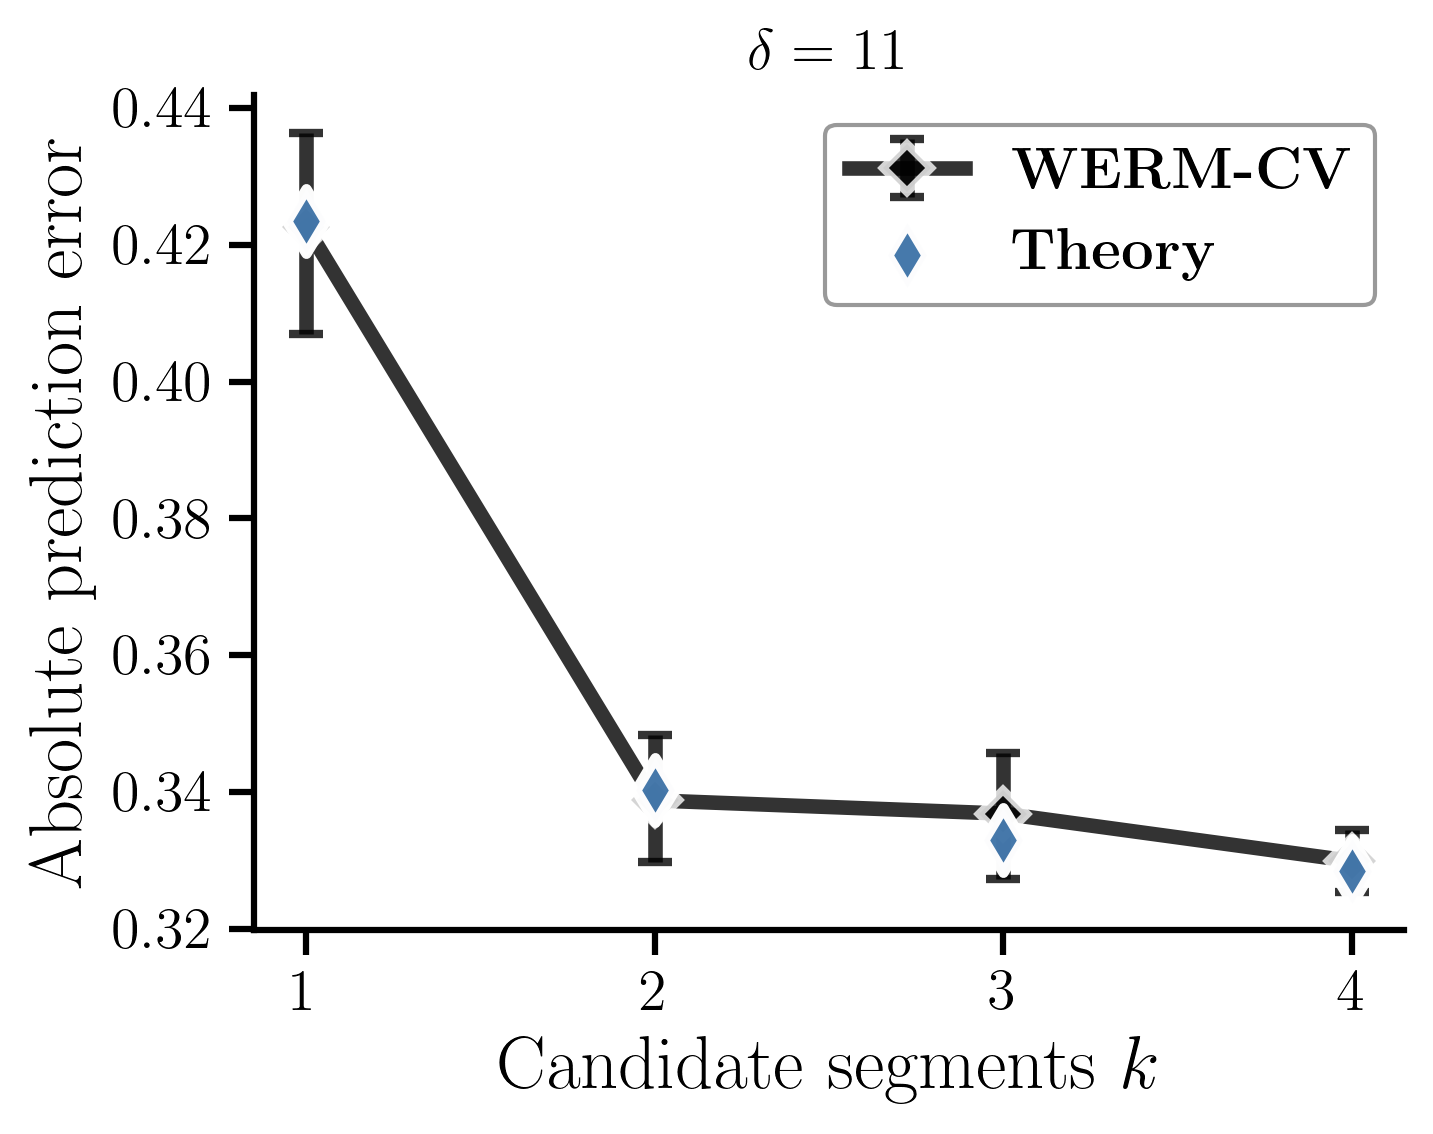

M2_scores_13


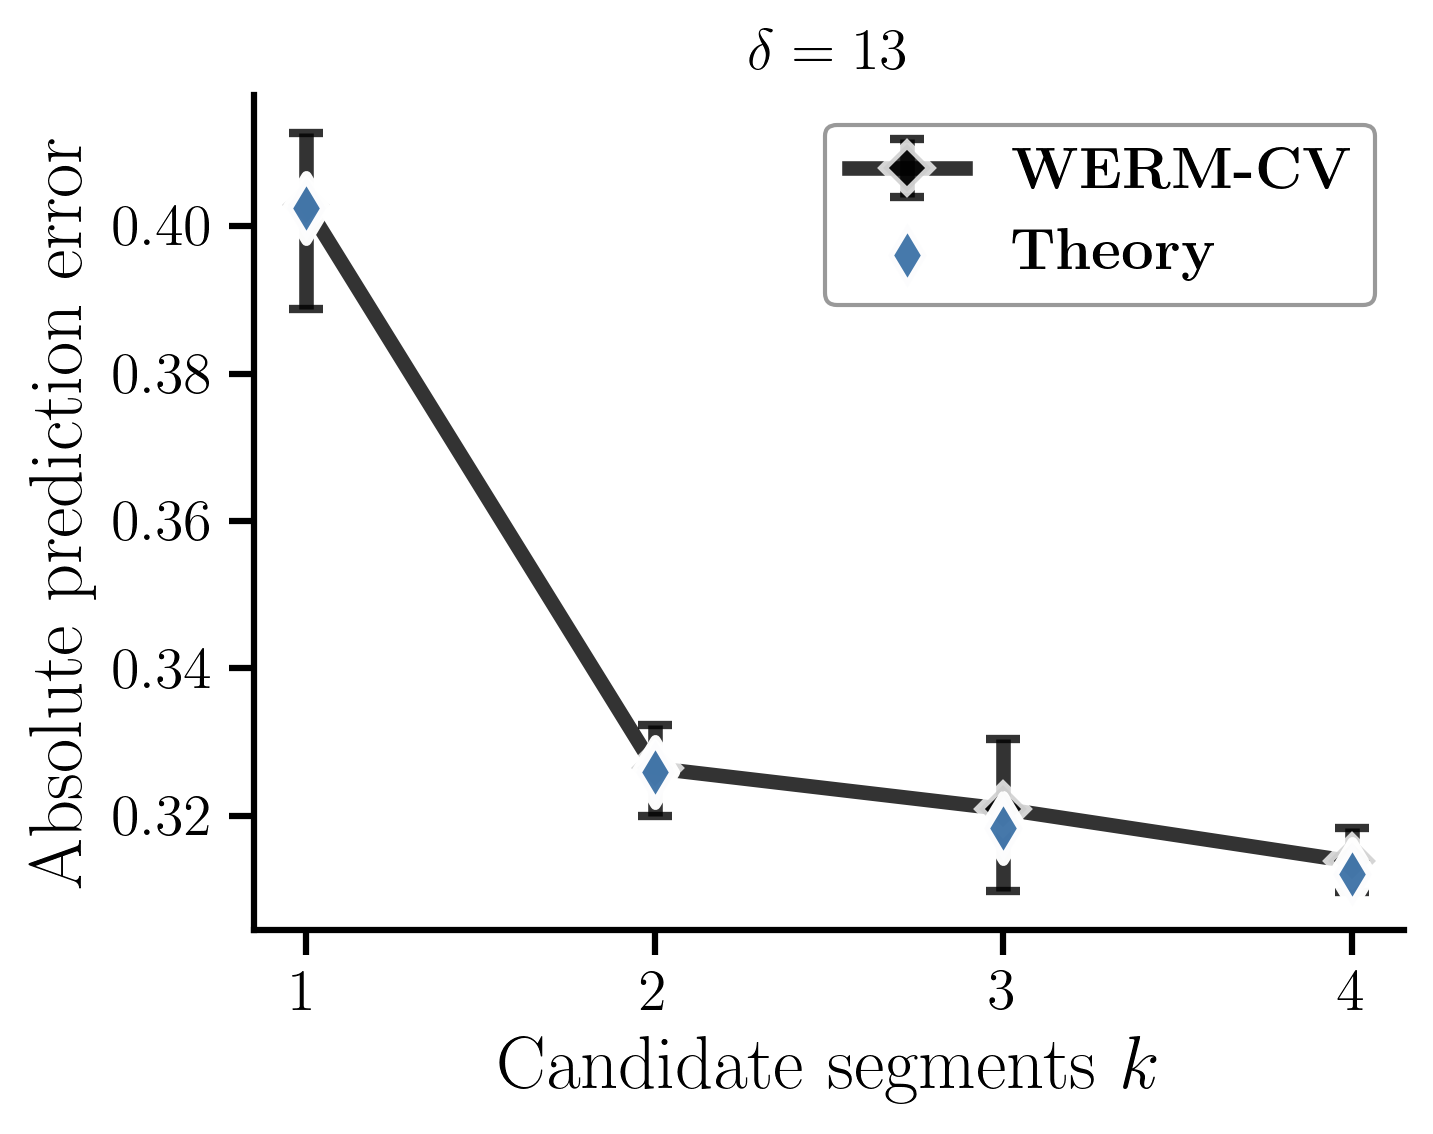

EL_scores_6


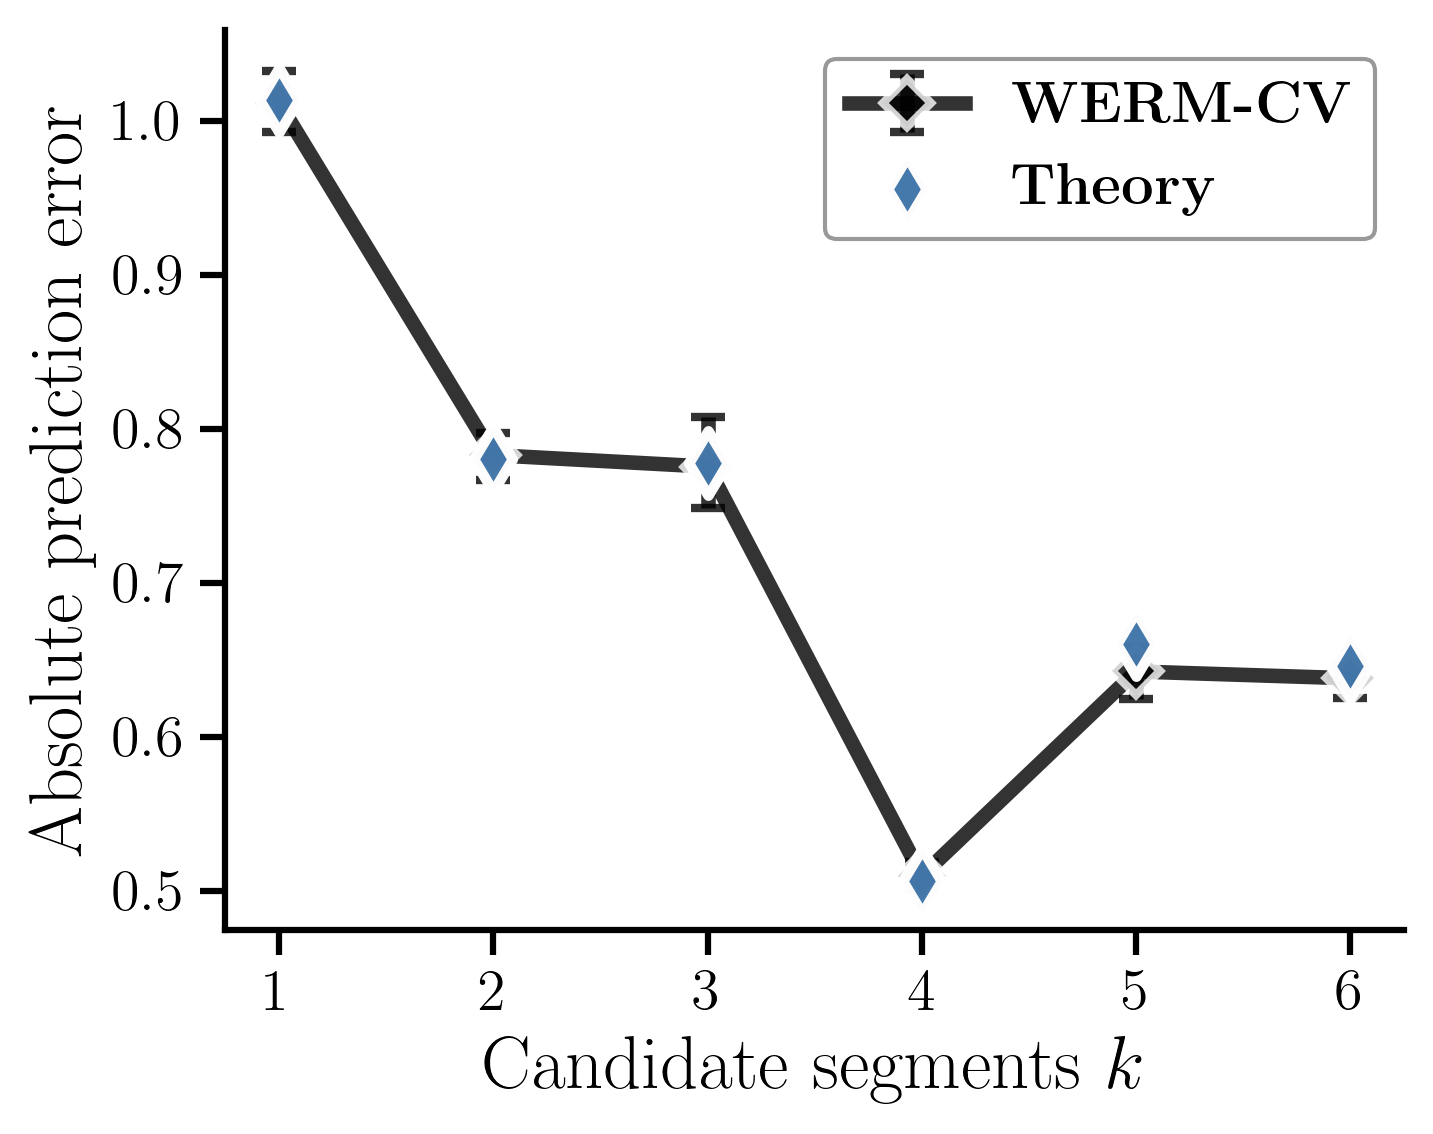

,experiment,x,count_agreement,mean_absolute_score_discrepancy,observed_vs_conditional_mae,conditional_vs_refit_se_mae,empirical_vs_theory_partition_risk_mae,median_empirical_gap,minimum_empirical_gap,median_theory_gap,minimum_theory_gap
0,M2,9.0,0.75,0.008882,0.007186,0.003601,0.004306,0.009130,0.000364,0.005815,0.000019
1,M2,11.0,0.65,0.006584,0.005674,0.002141,0.003344,0.006873,0.000167,0.006101,0.000023
2,M2,13.0,0.76,0.005929,0.004893,0.001835,0.002672,0.007068,0.000247,0.006604,0.000253
3,EL,6.0,1.00,0.016983,0.012759,0.006348,0.008772,0.121042,0.082687,0.140176,0.125548


In [3]:
score_rows=[]
for name in ('M2','EL'):
    slices=settings(name) if name=='M2' else [settings(name)[-1]]
    for x,records,bound in slices:
        empirical=np.array([r['empirical']['normalized_cv_scores'] for r in records])
        theory=np.array([r['theory']['normalized_cv_scores'] for r in records])
        counts=np.arange(1,empirical.shape[1]+1)
        emp_gap=np.diff(np.sort(empirical,axis=1)[:,:2],axis=1).ravel()
        se_gap=np.diff(np.sort(theory,axis=1)[:,:2],axis=1).ravel()
        conditional=np.array([r['conditional_validation_risk'] for r in records])
        refit_se=np.array([r['refit_se_at_empirical_partitions'] for r in records])
        score_rows.append(dict(experiment=name,x=x,
            count_agreement=np.mean(np.argmin(empirical,axis=1)==np.argmin(theory,axis=1)),
            mean_absolute_score_discrepancy=np.mean(np.abs(empirical-theory)),
            observed_vs_conditional_mae=np.mean(np.abs(empirical-conditional)),
            conditional_vs_refit_se_mae=np.mean(np.abs(conditional-refit_se)),
            empirical_vs_theory_partition_risk_mae=np.mean(np.abs(refit_se-theory)),
            median_empirical_gap=np.median(emp_gap),minimum_empirical_gap=emp_gap.min(),
            median_theory_gap=np.median(se_gap),minimum_theory_gap=se_gap.min()))
        with plt.rc_context(style.CANONICAL_STYLE):
            fig,ax=plt.subplots(figsize=(5,4));fig._canonical_m1=True
            style.error_series(ax,counts,empirical.T,LABELS[0],COLORS[0],'D','-',scale=1)
            ax.scatter(counts,theory.mean(axis=0),label=LABELS[1],marker='d',color=COLORS[1],
                       s=120,edgecolor='white',linewidth=2.5,alpha=.99,zorder=5)
            ax.set(xlabel=r'Candidate segments $k$',ylabel='Absolute prediction error',xticks=counts)
            if name=='M2':ax.set_title(rf'$\delta={x:g}$',fontsize=14)
            handles,labels=ax.get_legend_handles_labels()
            ax.legend([handles[labels.index(l)] for l in LABELS],LABELS,
                      loc='best',prop={'size':14},framealpha=.4)
            fig.tight_layout();style.export_plot(fig,f'{name}_scores_{x:g}')
SCORE_DIAGNOSTICS=pd.DataFrame(score_rows)
SCORE_DIAGNOSTICS.to_csv(ROOT/'notebook_score_diagnostics.csv',index=False)
display(SCORE_DIAGNOSTICS.round(6))

The extra risk diagnostics separate three sources of discrepancy:

- `observed_vs_conditional_mae`: observed validation error versus its exact
  conditional Gaussian expectation using the actual refitted coefficients.
- `conditional_vs_refit_se_mae`: that conditional risk versus uniform-refit SE
  evaluated at the **empirical** intervals.
- `empirical_vs_theory_partition_risk_mae`: refit SE at empirical intervals versus
  the full prediction using the SE-derived intervals.

These are diagnostic mean absolute discrepancies, not an additive decomposition
of error. The empirical intervals and coefficients enter **only these diagnostics**;
they never enter the main theory score, its count selection, or its final partition.
This distinguishes validation noise, refit-risk error, and partition-related error
when the overall match is imperfect.

## Numerical validity and provenance

The local-ratio audit includes the endpoint segments and all CV candidates,
not only the ultimately selected candidate. Uniform-refit SE requires $m_s/p>1$.
The theory's interval-selection and refit-stability assumptions remain separate
from these numerical checks. Source hashes and frozen marginal weights are stored
with the checkpoints; plotting verifies that its saved input file is unchanged.

In [4]:
diagnostic_rows=[dict(experiment=r['experiment'],delta=r['delta'],trial=r['trial'],
                      **r.get('diagnostics',{})) for r in RECORDS]
DIAGNOSTICS=pd.DataFrame(diagnostic_rows)
DIAGNOSTICS.to_csv(ROOT/'notebook_trial_diagnostics.csv',index=False)
display(DIAGNOSTICS.groupby(['experiment','delta']).agg(['min','max']))
assert len(RECORDS)==len(SPEC['settings'])*SPEC['trials']
assert len({(r['setting'],r['trial']) for r in RECORDS})==len(RECORDS)
assert all(r['p']>=200 and r['n']<3000 for r in RECORDS)
assert DIAGNOSTICS.min_empirical_segment_ratio.min()>1
assert DIAGNOSTICS.min_theory_segment_ratio.min()>1
assert DIAGNOSTICS.max_se_residual.max()<1e-9
assert all(np.isfinite(r[s]['normalized_cv_scores']).all() for r in RECORDS for s in ('empirical','theory'))
style.verify_sources()
print('Implementation: tools/werm_cv_theory_experiment.py and tools/werm_cv_empirical.py')
print('Existing M2 and E_L notebooks and their saved results were not modified.')

trial     min_empirical_segment_ratio         \
                   min max                         min    max   
experiment delta                                                
EL         12.0      0  99                         1.2  1.210   
M2         9.0       0  99                         1.2  1.665   
           11.0      0  99                         1.2  1.995   
           13.0      0  99                         1.2  2.420   

                 min_theory_segment_ratio       max_se_residual                \
                                      min   max             min           max   
experiment delta                                                                
EL         12.0                       1.2  1.20    2.159268e-14  3.596522e-14   
M2         9.0                        1.2  1.62    1.723778e-15  7.608475e-15   
           11.0                       1.2  1.98    3.015813e-15  7.952614e-15   
           13.0                       1.2  2.34    1.566050e-15  3.037883e-15   

                 max_refit_kkt               max_partition_kkt                \
                           min           max               min           max   
experiment delta                                                               
EL         12.0   1.500942e-17  2.821806e-17      1.308012e-17  2.518060e-17   
M2         9.0    1.336703e-17  2.480790e-17      1.409024e-17  2.997063e-17   
           11.0   1.026773e-17  2.471303e-17      1.248764e-17  2.801108e-17   
           13.0   8.871823e-18  1.950378e-17      1.191913e-17  2.746413e-17   

                 cv_score_mae            
                          min       max  
experiment delta                         
EL         12.0      0.006443  0.036973  
M2         9.0       0.000951  0.019254  
           11.0      0.000790  0.016159  
           13.0      0.002084  0.013952

Exported 8 figures to results/E-WERM-CV-theory/ed5fc8b279bb/figures; saved inputs unchanged.
Implementation: tools/werm_cv_theory_experiment.py and tools/werm_cv_empirical.py
Existing M2 and E_L notebooks and their saved results were not modified.


## M2: dimension and trial-count convergence

This follow-up investigates whether the original M2 discrepancy is finite-sample
error or Monte Carlo variation. The original 100-trial results and the E_L study
above are preserved. No model, location, sampling ratio, or seed is selected for
better agreement. The trial count is fixed before inspecting the new results.

Keep the original M2 generator, true fractions $(0.20,0.50)$, sampling ratios
$\delta\in\{9,11,13\}$, unpenalized 10-fold CV, and the same first-order theory
construction. Increase the dimension while keeping the **relative** segment
constraints fixed: the minimum training segment size scales as $1.2p$, including
the endpoint segments. The exact admissible-partition marginal weights are
recomputed at each dimension. Final full-data constraints use the corresponding
fraction and integer ceiling.

| Dimension $p$ | Sample sizes $n$ | Trials per setting | Minimum training segment size |
|---:|---|---:|---:|
| 200 | 1800, 2200, 2600 | 300 | 240 |
| 220 | 1980, 2420, 2860 | 300 | 264 |

The $p=200$ follow-up extends the original run: its first 100 datasets are reused
exactly, followed by additional trial IDs. It is therefore **not independent** of
the original 100-trial estimate. Different dimensions use their documented seed
streams; no trial pairing across dimensions is asserted. Empirical and theoretical
outcomes are paired within each dataset.

Larger trial counts reduce uncertainty in the plotted means, but do not remove
bias in a first-order approximation. Increasing dimension may reduce partition
fluctuations at fixed sampling ratios; any persistent discrepancy remains visible.
The 20 final SE draws per dataset are retained: increasing them would address
Monte Carlo error in the final-location prediction, not the CV-selection step.

In [1]:
# Self-contained follow-up. Completed checkpoints are reused.
import os, pickle
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from tools import m2_cv_theory_convergence as convergence
from tools import werm_cv_theory_experiment as cv_experiment
import tools.consistent_plotting as cv_style
import matplotlib.pyplot as plt
CV_DIMENSIONS = [200, 220]
CV_TRIALS = 300
CV_RUNS = {}
for p in CV_DIMENSIONS:
    root,spec,weights = convergence.prepare(p=p,trials=CV_TRIALS)
    if not (root/'results.pkl').exists():
        cv_experiment.run(root,spec,weights,jobs=int(os.environ.get('WERM_CV_THEORY_JOBS','12')))
    CV_RUNS[p] = (root,spec)
CV_OUTPUT = CV_RUNS[max(CV_DIMENSIONS)][0]
cv_style.OUTPUT_DIR = CV_OUTPUT/'figures'
cv_style.SOURCE_HASHES.clear();cv_style.FIGURE_AUDIT.clear()
CV_ORIGINAL = cv_style.load_saved(convergence.PARENT/'results.pkl')
CV_FOLLOWUPS = {p:cv_style.load_saved(root/'results.pkl') for p,(root,spec) in CV_RUNS.items()}
CV_LABELS = (r'\textbf{WERM-CV}',r'\textbf{Theory}')
CV_COLORS = ('black','#4477AA')
print('Follow-up result directories:',{p:str(v[0]) for p,v in CV_RUNS.items()})

Follow-up result directories: {200: 'results/M2_CV_theory_convergence/p200_6961bbb9765c', 220: 'results/M2_CV_theory_convergence/p220_1b81123e021c'}


### Aggregate agreement and its Monte Carlo uncertainty

Each row compares the empirical and theory means over datasets. Differences are
**Theory minus WERM-CV**. Their standard errors use the paired per-dataset
differences, with the theory's 20 final-location draws averaged within each
dataset. This treats the signal matrix as the independent sampling unit rather
than counting all theory draws as independent datasets.

Count agreement reports the fraction of individual datasets with the same CV
selection; it is distinct from agreement of mean-count curves. Hausdorff means
are normalized by $n$. If empty estimates occur, their numbers and the number of
finite pairs are retained explicitly.

In [2]:
def cv_records(payload,delta):
    return [r for r in payload['records'] if r['experiment']=='M2' and r['delta']==delta]

def cv_vectors(records):
    empirical_count=np.array([r['empirical']['selected_by_bound'][4]['selected_segments']-1 for r in records],float)
    theory_count=np.array([r['theory']['selected_by_bound'][4]['selected_segments']-1 for r in records],float)
    empirical_haus=np.array([r['empirical']['selected_by_bound'][4]['haus'] for r in records],float)
    theory_haus=[]
    for r in records:
        h=np.array([f['haus'] for f in r['theory']['selected_by_bound'][4]['final_fits']],float)
        theory_haus.append(h[np.isfinite(h)].mean() if np.isfinite(h).any() else np.nan)
    return empirical_count,theory_count,empirical_haus,np.array(theory_haus)

def finite_mean(values):
    values=np.asarray(values);values=values[np.isfinite(values)]
    return values.mean() if len(values) else np.nan

def paired_summary(a,b):
    valid=np.isfinite(a)&np.isfinite(b);d=(b-a)[valid]
    return (d.mean() if len(d) else np.nan,
            d.std(ddof=1)/np.sqrt(len(d)) if len(d)>1 else np.nan,len(d))

CV_COMPARISON_ROWS=[]
for label,payload in [('Original 100 trials',CV_ORIGINAL)]+[(f'p={p}, {CV_TRIALS} trials',v) for p,v in CV_FOLLOWUPS.items()]:
    for delta in (9.,11.,13.):
        records=cv_records(payload,delta)
        ec,tc,eh,th=cv_vectors(records)
        count_diff,count_se,count_pairs=paired_summary(ec,tc)
        haus_diff,haus_se,haus_pairs=paired_summary(eh,th)
        empirical_scores=np.array([r['empirical']['normalized_cv_scores'] for r in records])
        theory_scores=np.array([r['theory']['normalized_cv_scores'] for r in records])
        CV_COMPARISON_ROWS.append(dict(run=label,p=records[0]['p'],n=records[0]['n'],delta=delta,
            trials=len(records),empirical_count=ec.mean(),theory_count=tc.mean(),
            count_difference=count_diff,count_difference_se=count_se,
            individual_count_agreement=np.mean(ec==tc),
            empirical_haus=finite_mean(eh),theory_haus=finite_mean(th),
            haus_difference=haus_diff,haus_difference_se=haus_se,finite_haus_pairs=haus_pairs,
            empirical_empty=int(np.sum(ec==0)),theory_empty=int(np.sum(tc==0)),
            mean_absolute_candidate_score_error=np.mean(np.abs(empirical_scores-theory_scores))))
CV_COMPARISON=pd.DataFrame(CV_COMPARISON_ROWS)
CV_COMPARISON.to_csv(CV_OUTPUT/'convergence_comparison.csv',index=False)
with pd.option_context('display.max_columns',None,'display.width',180):
    display(CV_COMPARISON.round(6))

,run,p,n,delta,trials,empirical_count,theory_count,count_difference,count_difference_se,individual_count_agreement,empirical_haus,theory_haus,haus_difference,haus_difference_se,finite_haus_pairs,empirical_empty,theory_empty,mean_absolute_candidate_score_error
0,Original 100 trials,200,1800,9.0,100,1.950000,2.040000,0.090000,0.069769,0.750000,0.207933,0.210629,0.002696,0.009363,100,0,0,0.008882
1,Original 100 trials,200,2200,11.0,100,2.290000,2.480000,0.190000,0.078746,0.650000,0.199300,0.181767,-0.017533,0.010650,100,0,0,0.006584
2,Original 100 trials,200,2600,13.0,100,2.490000,2.550000,0.060000,0.060000,0.760000,0.159996,0.159695,-0.000302,0.008835,100,0,0,0.005929
3,"p=200, 300 trials",200,1800,9.0,300,1.940000,1.960000,0.020000,0.042743,0.723333,0.219061,0.218808,-0.000253,0.005658,300,0,0,0.009108
4,"p=200, 300 trials",200,2200,11.0,300,2.240000,2.450000,0.210000,0.045753,0.660000,0.186271,0.184529,-0.001742,0.005966,300,0,0,0.006842
5,"p=200, 300 trials",200,2600,13.0,300,2.400000,2.500000,0.100000,0.040482,0.720000,0.151765,0.146824,-0.004941,0.005359,300,0,0,0.005915
6,"p=220, 300 trials",220,1980,9.0,300,1.870000,1.990000,0.120000,0.052759,0.603333,0.222874,0.219648,-0.003225,0.006401,300,0,0,0.008172
7,"p=220, 300 trials",220,2420,11.0,300,2.336667,2.516667,0.180000,0.048418,0.646667,0.184588,0.188309,0.003720,0.006027,300,0,0,0.006932
8,"p=220, 300 trials",220,2860,13.0,300,2.486667,2.590000,0.103333,0.043251,0.690000,0.171061,0.159022,-0.012039,0.005798,300,0,0,0.005565


### Follow-up curves at each dimension

Each dimension is displayed separately. WERM-CV retains the canonical black
curve and empirical quartile bars. Theory is a blue diamond scatter overlay,
with no connecting lines or error bars. Theory location means average the final
draws within each dataset first, then average over datasets. These figures do
not replace or conceal the original 100-trial curves above.

M2_p200_count_convergence


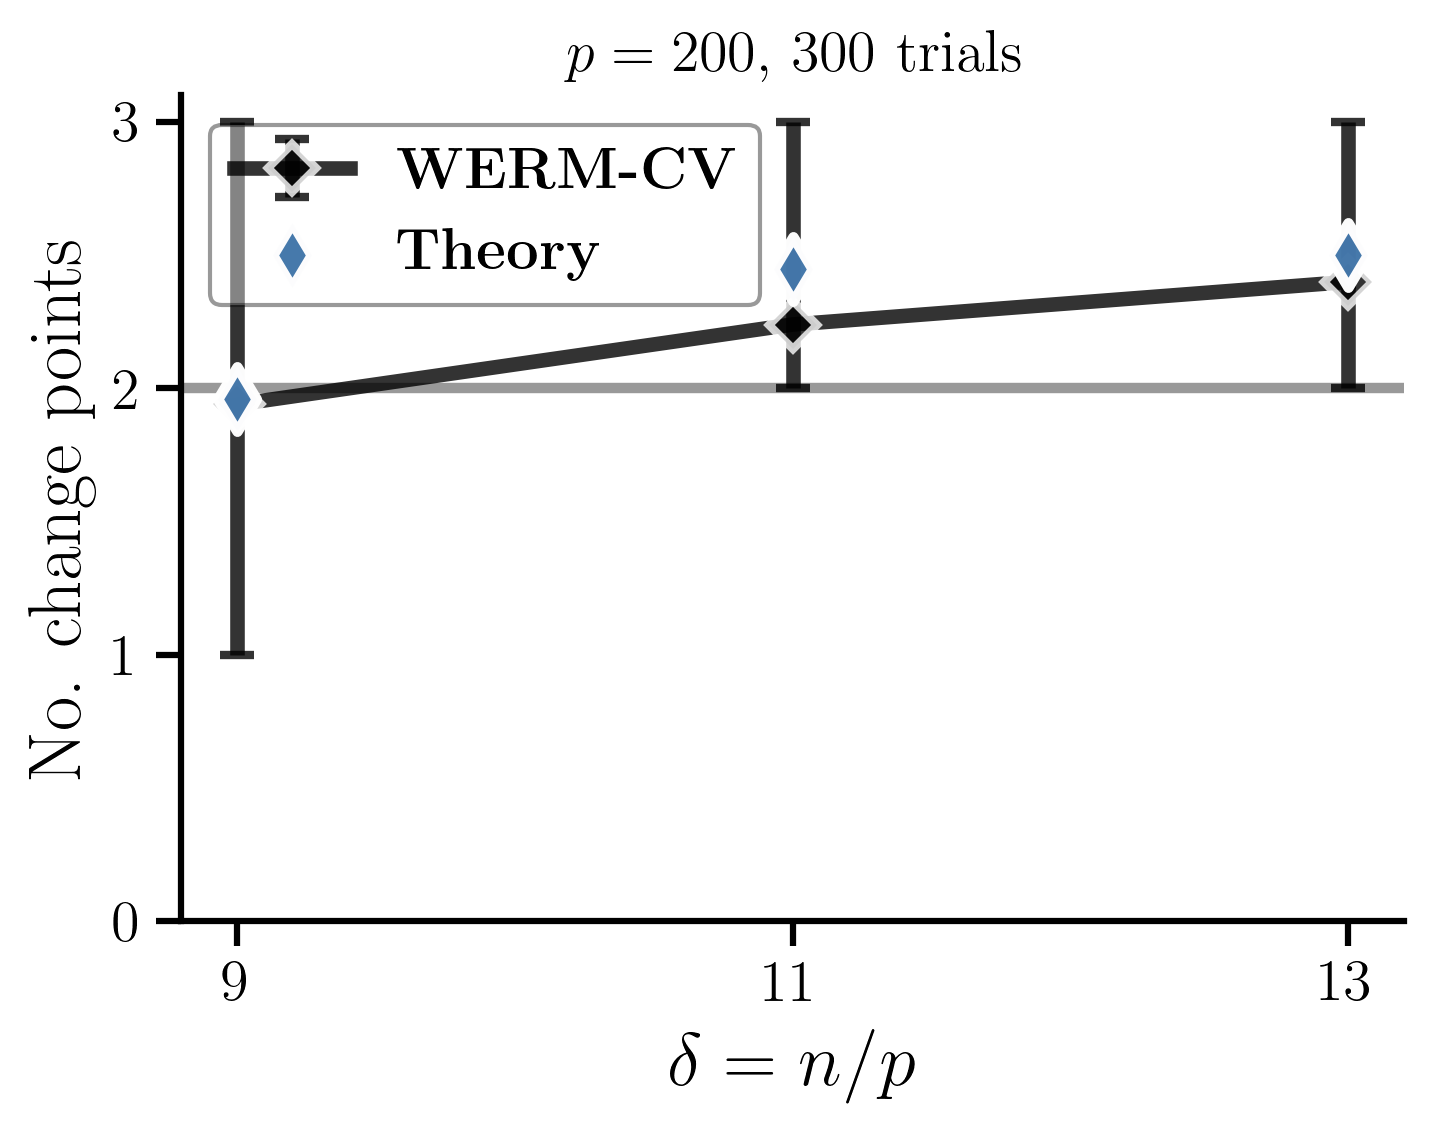

M2_p200_haus_convergence


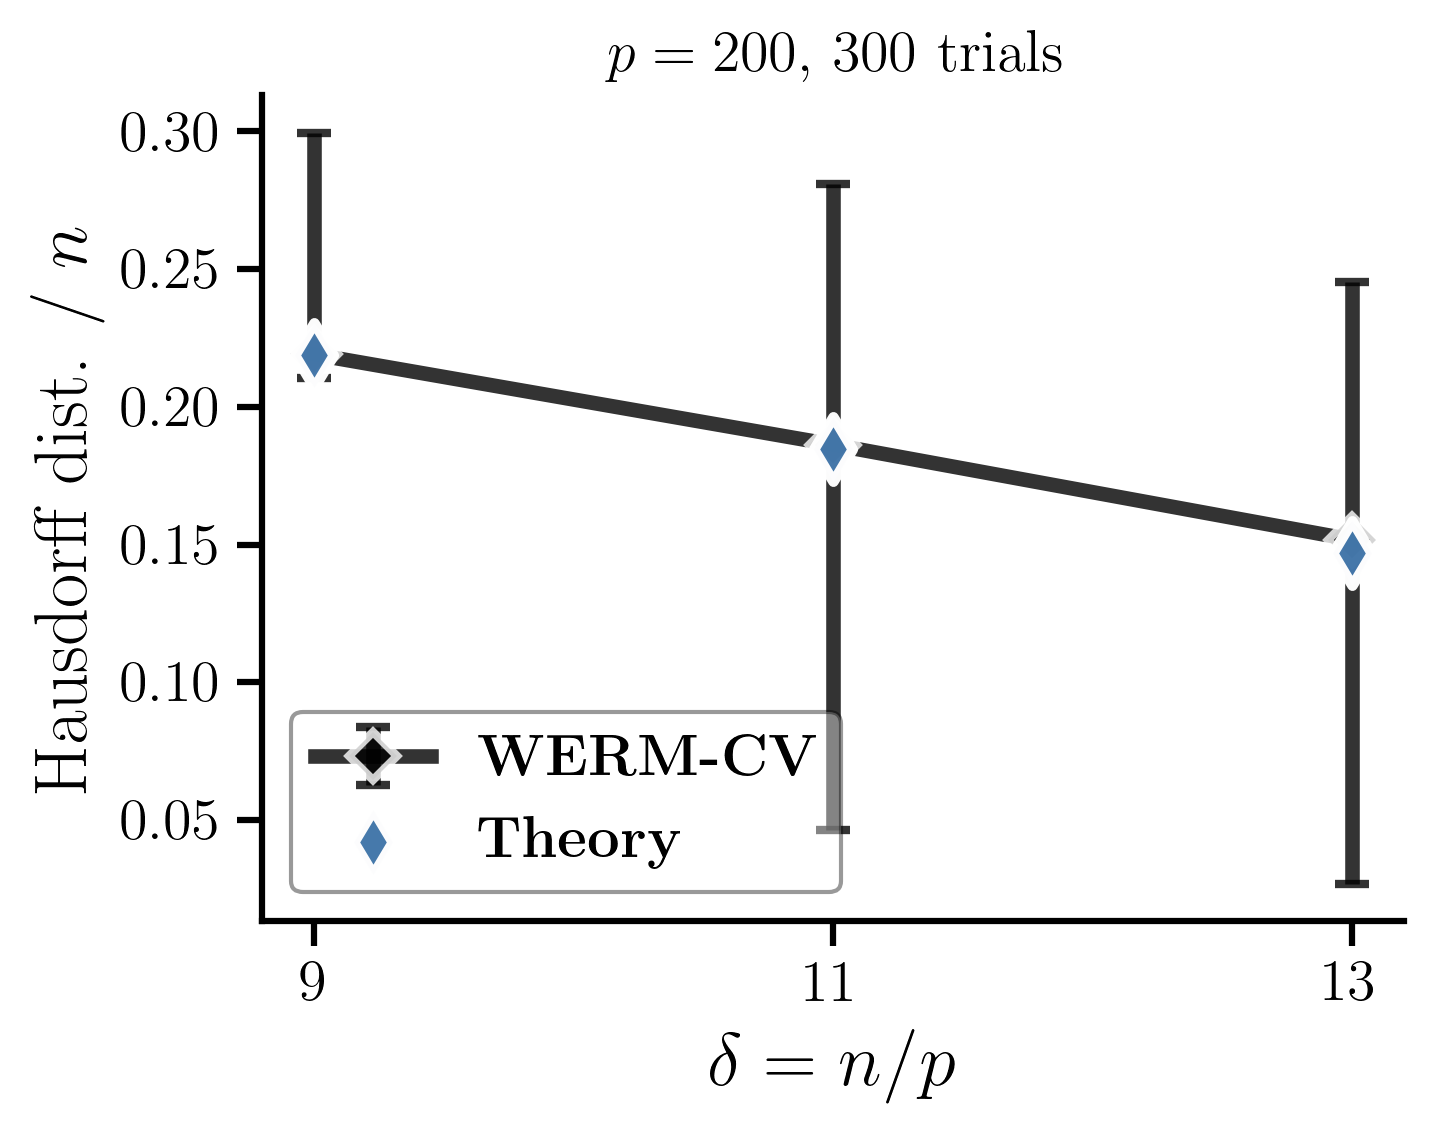

M2_p220_count_convergence


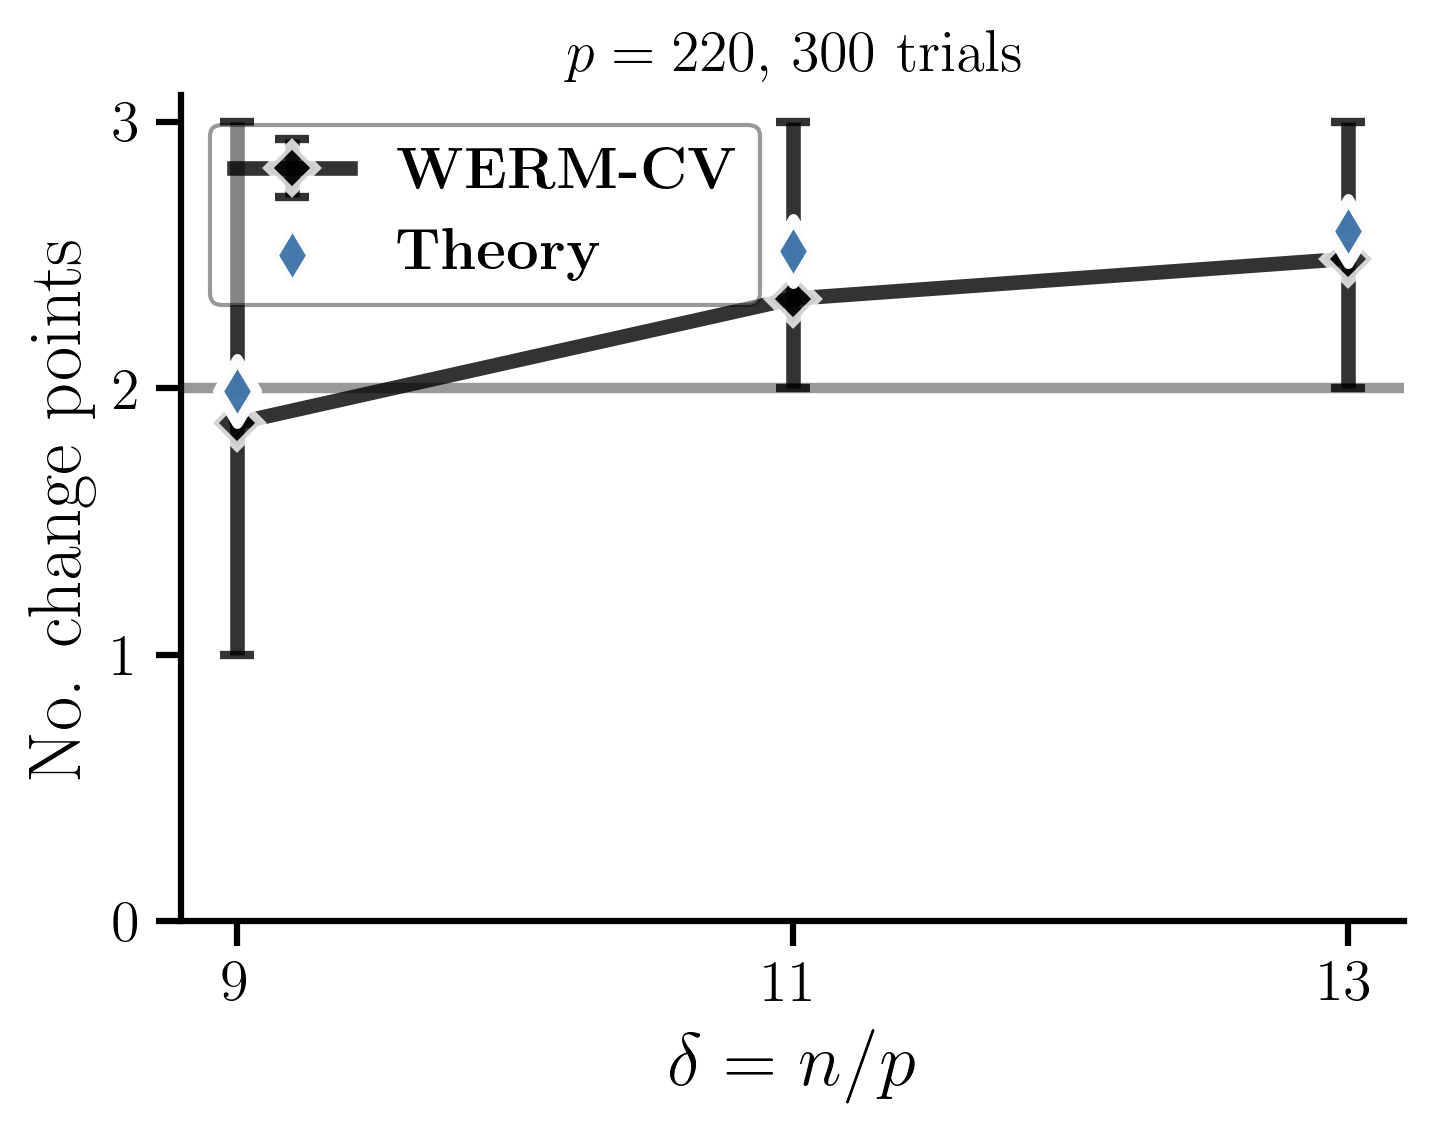

M2_p220_haus_convergence


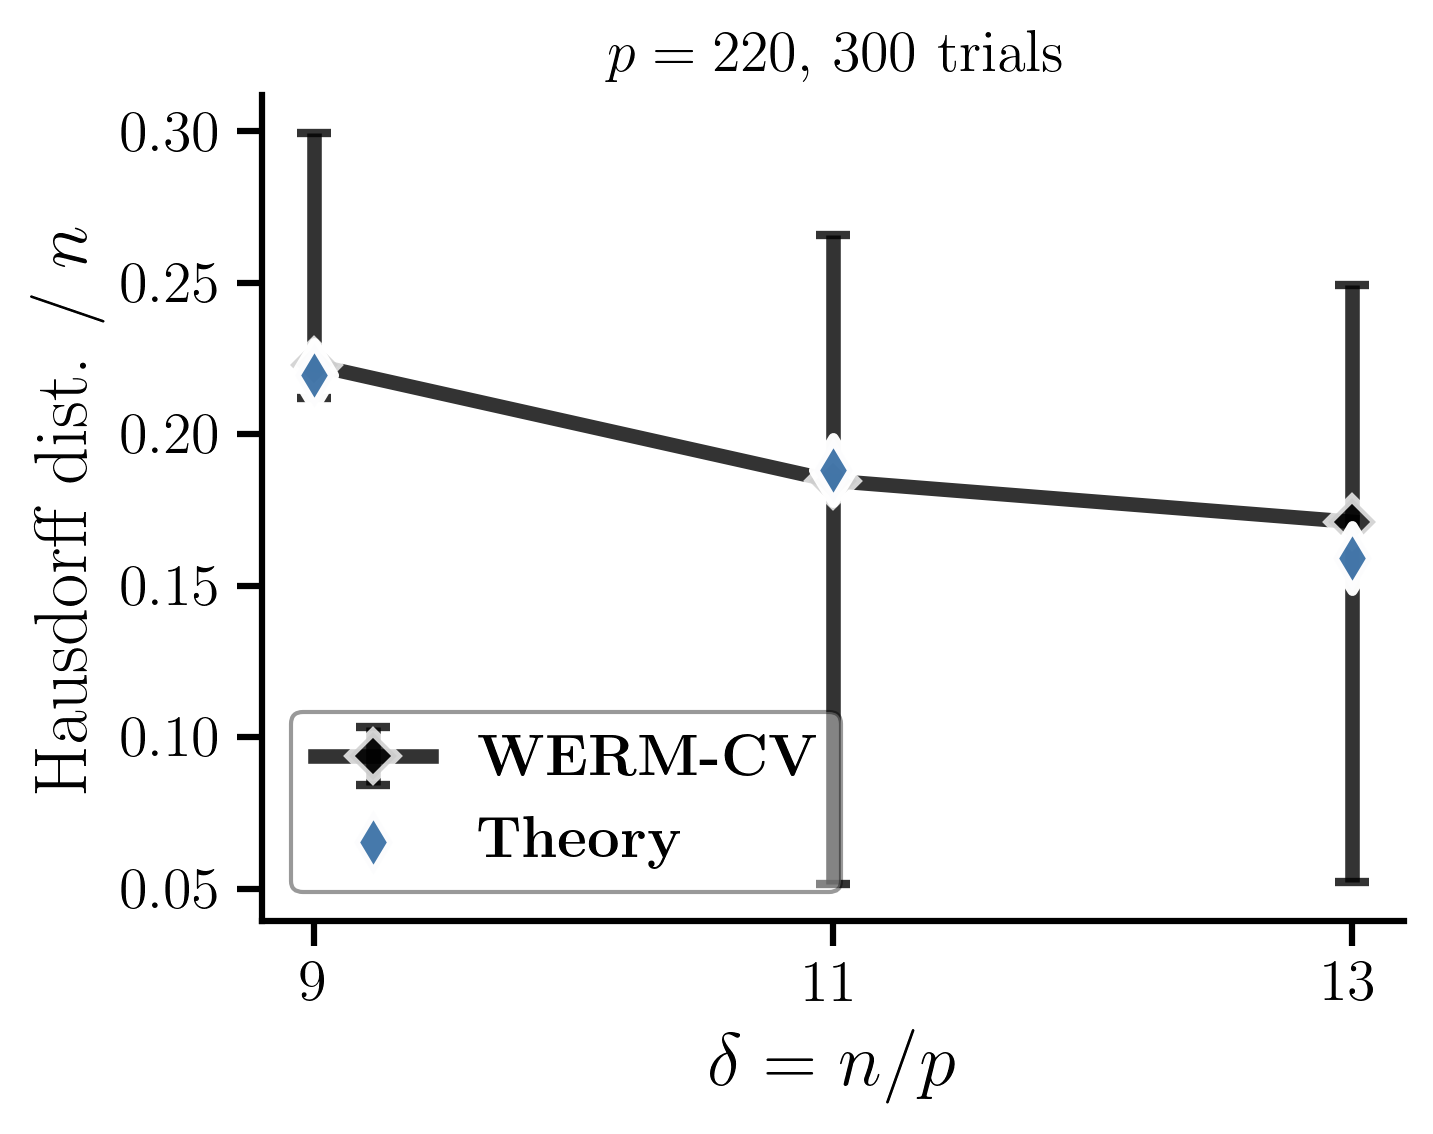

Exported 4 figures to results/M2_CV_theory_convergence/p220_1b81123e021c/figures; saved inputs unchanged.


In [3]:
def cv_followup_plot(p,payload):
    deltas=(9.,11.,13.)
    vectors=[cv_vectors(cv_records(payload,d)) for d in deltas]
    for metric,emp_index,theory_index,ylabel in [('count',0,1,'No. change points'),
            ('haus',2,3,r'Hausdorff dist. / $n$')]:
        with plt.rc_context(cv_style.CANONICAL_STYLE):
            fig,ax=plt.subplots(figsize=(5,4));fig._canonical_m1=True
            cv_style.error_series(ax,deltas,[v[emp_index] for v in vectors],
                CV_LABELS[0],CV_COLORS[0],'D','-',scale=1)
            ax.scatter(deltas,[finite_mean(v[theory_index]) for v in vectors],
                label=CV_LABELS[1],marker='d',color=CV_COLORS[1],s=120,
                edgecolor='white',linewidth=2.5,alpha=.99,zorder=5)
            ax.set(xlabel=r'$\delta=n/p$',ylabel=ylabel,xticks=deltas)
            ax.set_title(rf'$p={p}$, {CV_TRIALS} trials',fontsize=14)
            if metric=='count':
                ax.axhline(2,color='gray',lw=2.5,alpha=.8,zorder=0)
                ax.set_yticks(range(4))
            handles,labels=ax.get_legend_handles_labels()
            ax.legend([handles[labels.index(l)] for l in CV_LABELS],CV_LABELS,
                loc='best',prop={'size':14},framealpha=.4)
            fig.tight_layout();cv_style.export_plot(fig,f'M2_p{p}_{metric}_convergence')
for p,payload in CV_FOLLOWUPS.items():
    cv_followup_plot(p,payload)
cv_style.verify_sources()

### Candidate-score check at the largest dimension

These score curves show every candidate, not only the selected one. The
diagnostics separate observed validation noise, uniform-refit risk approximation,
and the effect of replacing empirical training partitions with the theoretical
limiting partitions. Empirical coefficients and intervals enter only the diagnostic
calculations; the main Theory prediction and count selection never use them.

M2_p220_scores_9_convergence


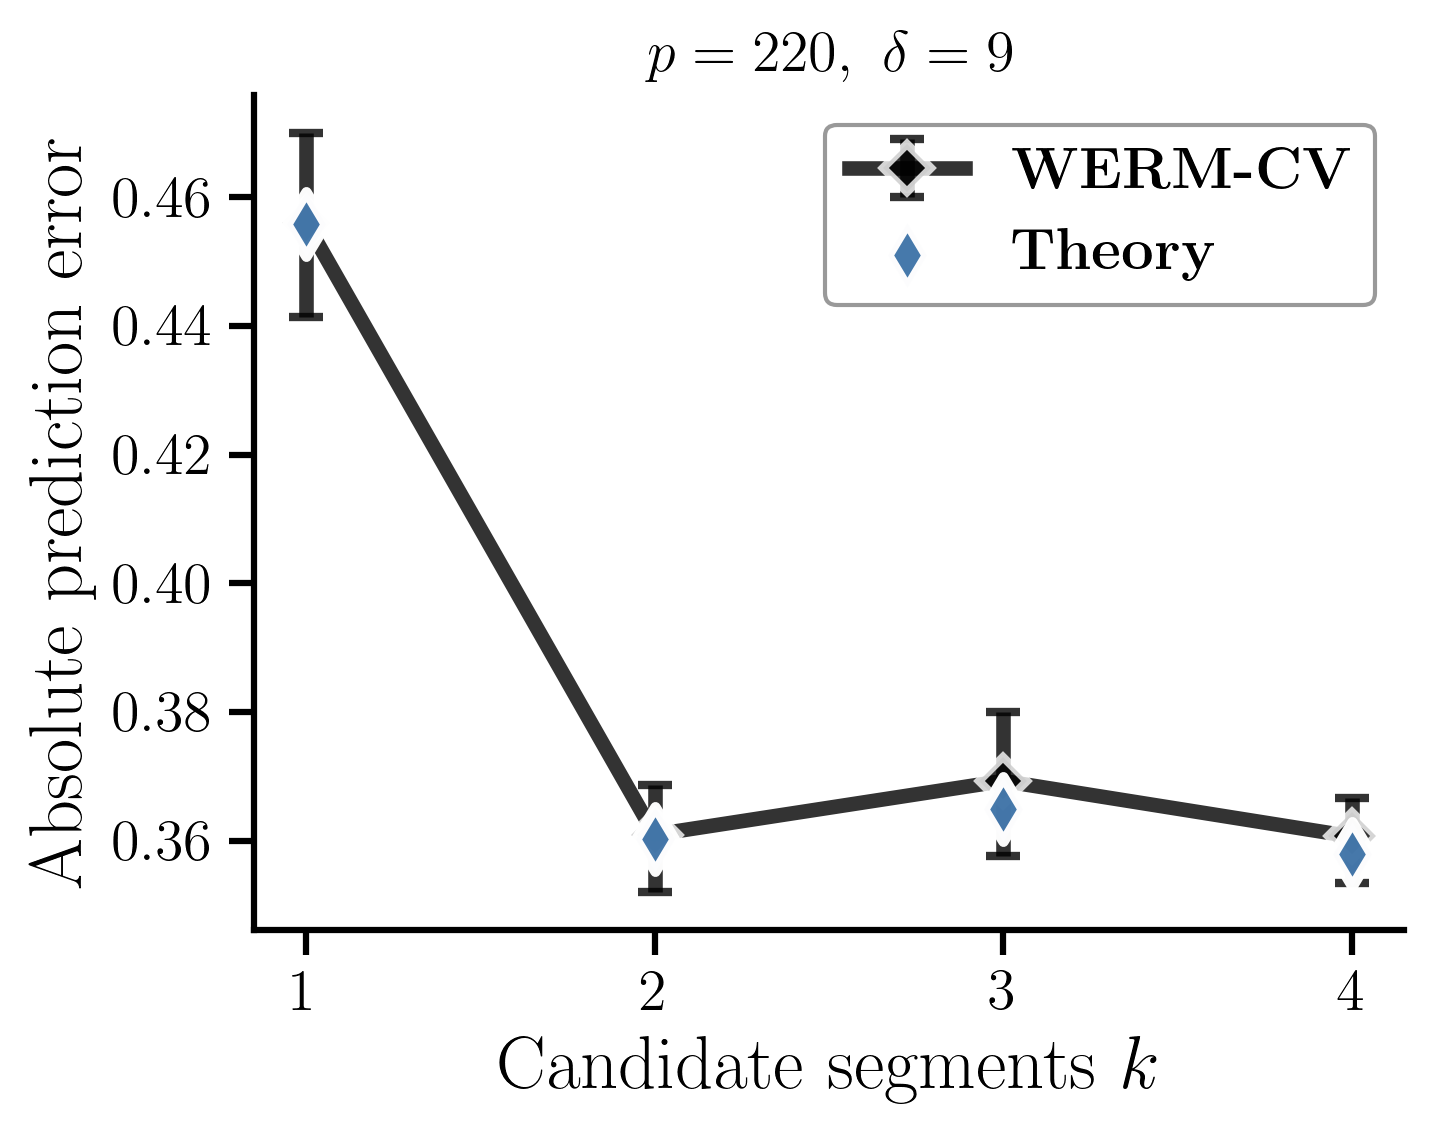

M2_p220_scores_11_convergence


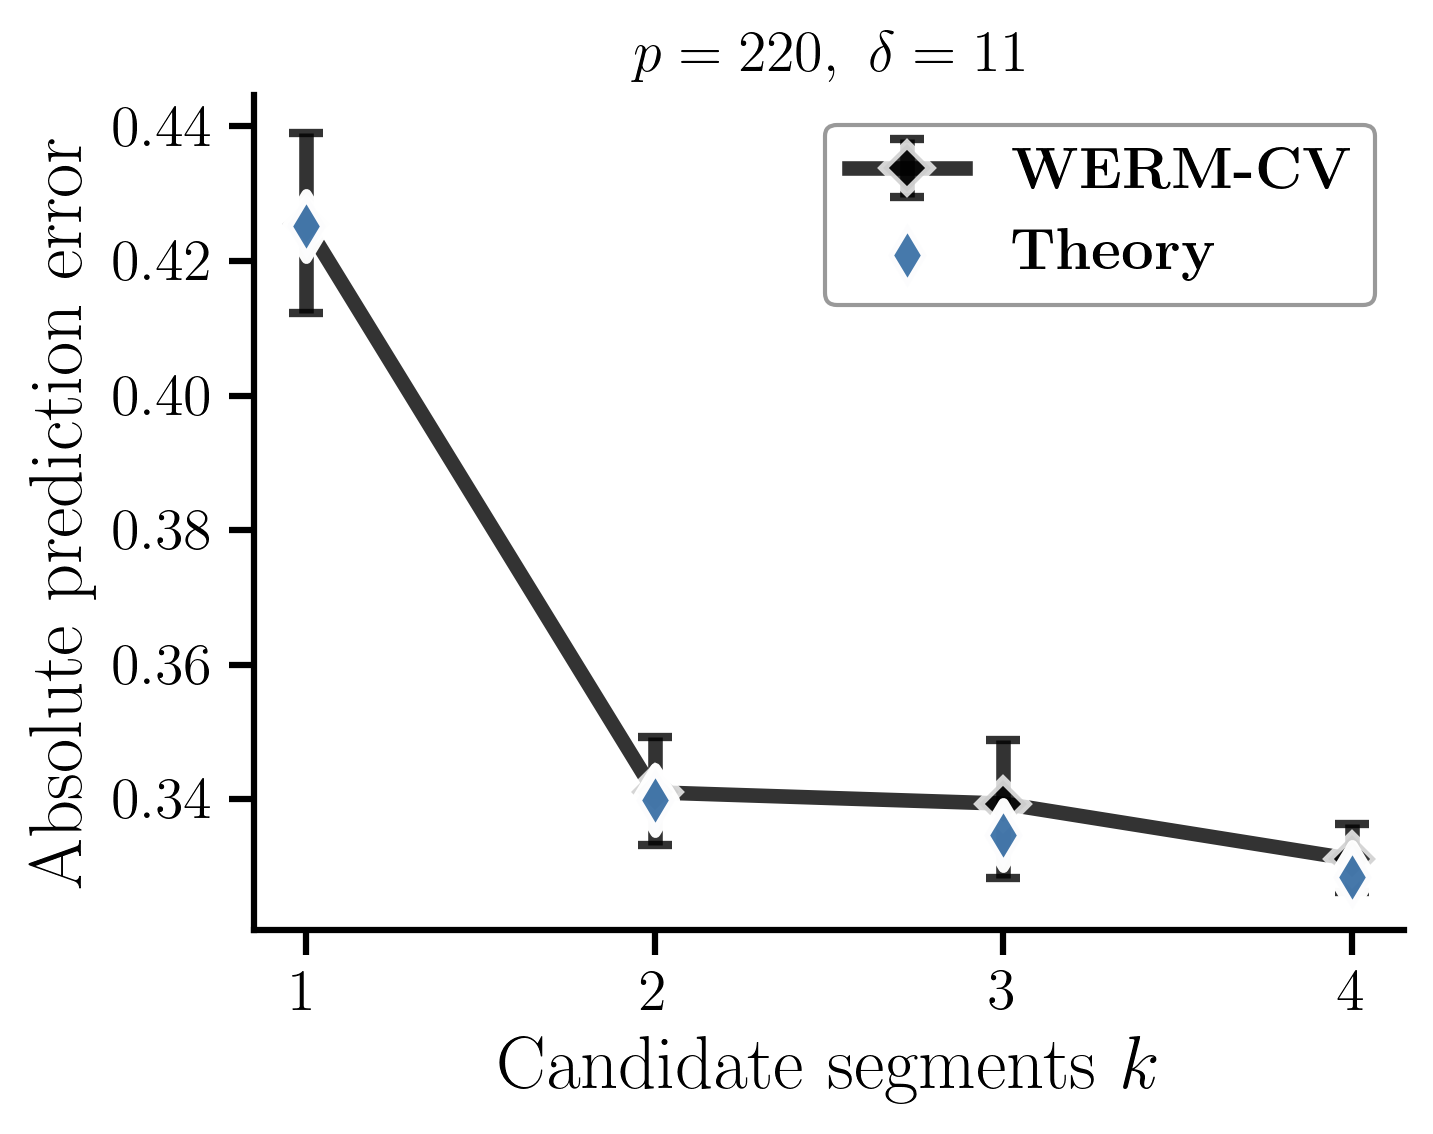

M2_p220_scores_13_convergence


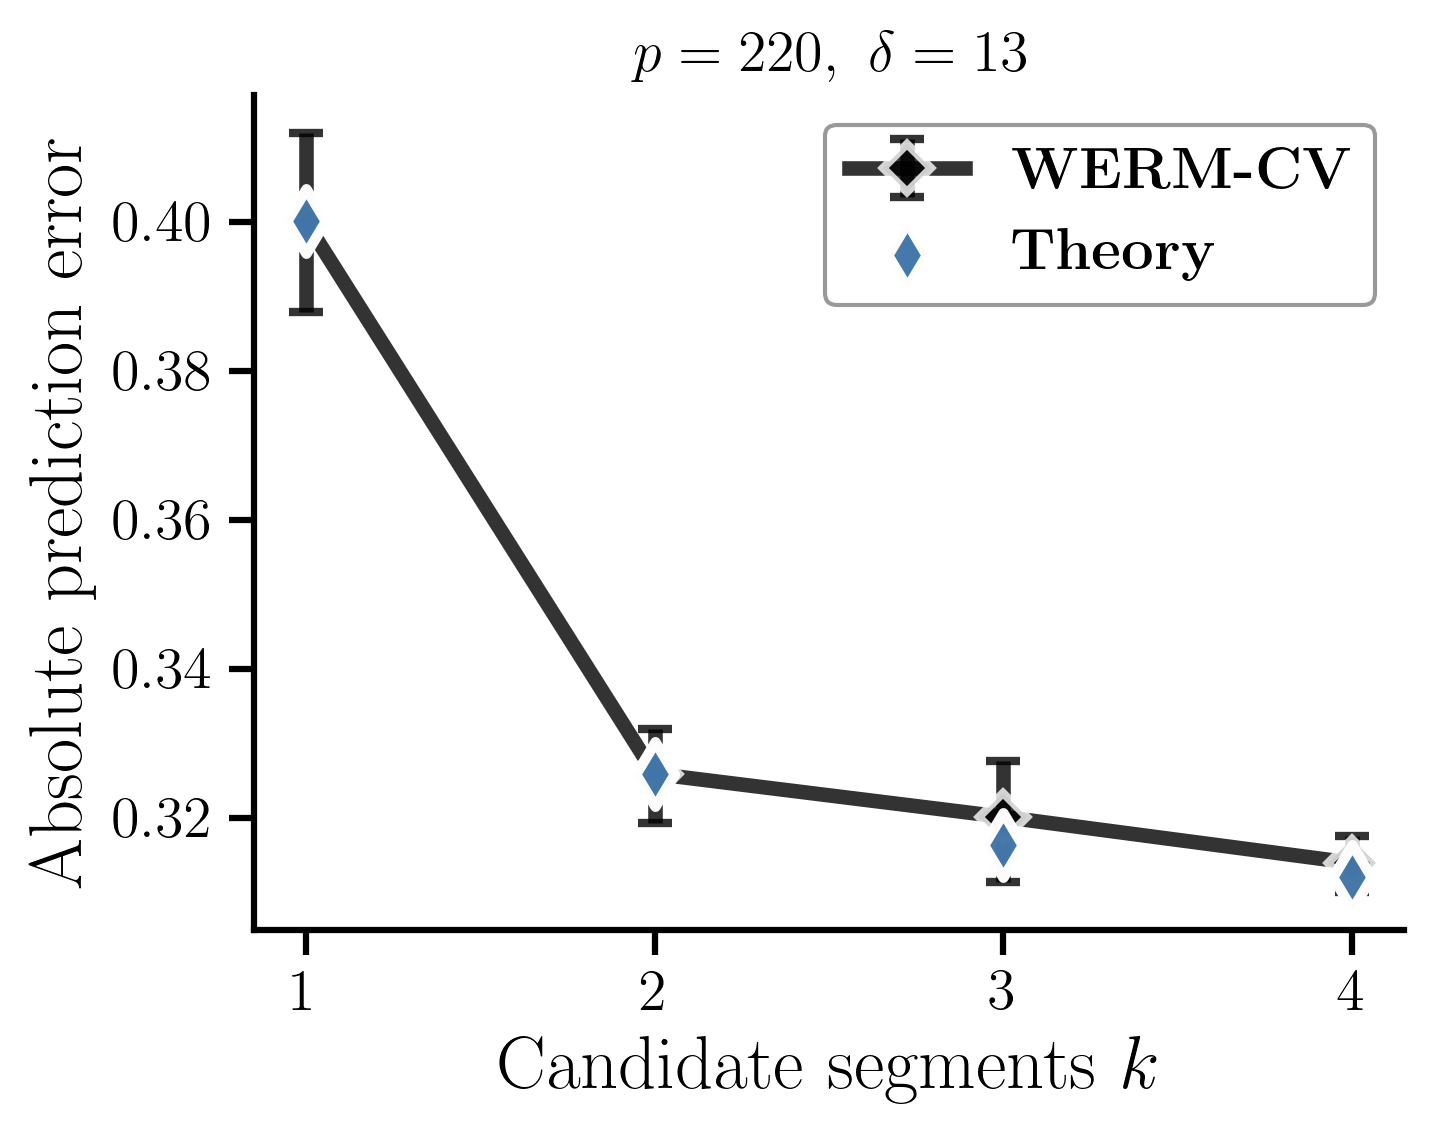

,p,delta,observed_vs_conditional_mae,conditional_vs_refit_se_mae,empirical_vs_theory_partition_risk_mae,median_theory_selection_gap,min_empirical_segment_ratio,min_theory_segment_ratio,max_se_residual
0,200,9.0,0.007341,0.003417,0.004123,0.005615,1.2,1.2,0.0
1,200,11.0,0.005677,0.002360,0.003236,0.006152,1.2,1.2,0.0
2,200,13.0,0.004897,0.001817,0.002648,0.006447,1.2,1.2,0.0
3,220,9.0,0.007124,0.003158,0.003835,0.005108,1.2,1.2,0.0
4,220,11.0,0.005381,0.002269,0.003317,0.005732,1.2,1.2,0.0
5,220,13.0,0.004461,0.001674,0.002505,0.006849,1.2,1.2,0.0


Exported 7 figures to results/M2_CV_theory_convergence/p220_1b81123e021c/figures; saved inputs unchanged.
Original M2 and E_L cells and outputs were preserved.


In [4]:
CV_STAGE_ROWS=[]
for p,payload in CV_FOLLOWUPS.items():
    for delta in (9.,11.,13.):
        records=cv_records(payload,delta)
        observed=np.array([r['empirical']['normalized_cv_scores'] for r in records])
        predicted=np.array([r['theory']['normalized_cv_scores'] for r in records])
        conditional=np.array([r['conditional_validation_risk'] for r in records])
        refit=np.array([r['refit_se_at_empirical_partitions'] for r in records])
        sorted_risks=np.sort(predicted,axis=1)
        CV_STAGE_ROWS.append(dict(p=p,delta=delta,
            observed_vs_conditional_mae=np.abs(observed-conditional).mean(),
            conditional_vs_refit_se_mae=np.abs(conditional-refit).mean(),
            empirical_vs_theory_partition_risk_mae=np.abs(refit-predicted).mean(),
            median_theory_selection_gap=np.median(sorted_risks[:,1]-sorted_risks[:,0]),
            min_empirical_segment_ratio=min(r['diagnostics']['min_empirical_segment_ratio'] for r in records),
            min_theory_segment_ratio=min(r['diagnostics']['min_theory_segment_ratio'] for r in records),
            max_se_residual=max(r['diagnostics']['max_se_residual'] for r in records)))
        if p!=max(CV_DIMENSIONS):continue
        with plt.rc_context(cv_style.CANONICAL_STYLE):
            fig,ax=plt.subplots(figsize=(5,4));fig._canonical_m1=True
            k=np.arange(1,5)
            cv_style.error_series(ax,k,observed.T,CV_LABELS[0],CV_COLORS[0],'D','-',scale=1)
            ax.scatter(k,predicted.mean(axis=0),label=CV_LABELS[1],marker='d',color=CV_COLORS[1],
                s=120,edgecolor='white',linewidth=2.5,alpha=.99,zorder=5)
            ax.set(xlabel=r'Candidate segments $k$',ylabel='Absolute prediction error',xticks=k)
            ax.set_title(rf'$p={p},\ \delta={delta:g}$',fontsize=14)
            handles,labels=ax.get_legend_handles_labels()
            ax.legend([handles[labels.index(l)] for l in CV_LABELS],CV_LABELS,
                loc='best',prop={'size':14},framealpha=.4)
            fig.tight_layout();cv_style.export_plot(fig,f'M2_p{p}_scores_{delta:g}_convergence')
CV_STAGE_DIAGNOSTICS=pd.DataFrame(CV_STAGE_ROWS)
CV_STAGE_DIAGNOSTICS.to_csv(CV_OUTPUT/'convergence_stage_diagnostics.csv',index=False)
display(CV_STAGE_DIAGNOSTICS.round(6))
assert CV_STAGE_DIAGNOSTICS.min_empirical_segment_ratio.min()>=1.2-1e-12
assert CV_STAGE_DIAGNOSTICS.min_theory_segment_ratio.min()>=1.2-1e-12
assert CV_STAGE_DIAGNOSTICS.max_se_residual.max()<1e-9
assert all(len(v['records'])==3*CV_TRIALS for v in CV_FOLLOWUPS.values())
cv_style.verify_sources()
print('Original M2 and E_L cells and outputs were preserved.')